## Mira primero: una plantilla, tres planos

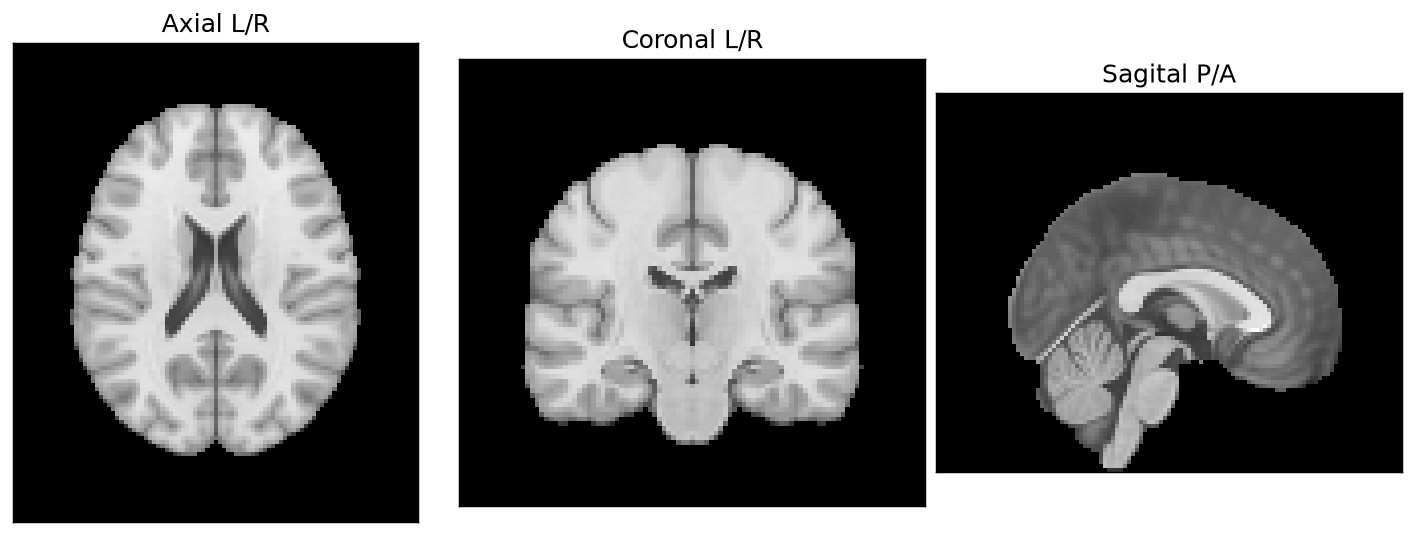

**Estas imágenes ya están aquí:** puedes observarlas sin ejecutar ni instalar nada. Son tres cortes de la misma plantilla de referencia, no tres pacientes. Después sigue la ruta y ejecuta el código para reproducirlas.


# Imágenes médicas desde cero
## 1 Primero miremos las imágenes
Abre la salida de esta primera celda: verás tres vistas de **la misma plantilla cerebral pública**. No es un estudio de un paciente. Las salidas ya están guardadas; puedes mirar antes de ejecutar. Para reproducir, usa Mayús + Enter. La primera ejecución instala bibliotecas solo si faltan; necesita internet en ese caso. El código completo está a la vista y se explica inmediatamente después de la imagen.

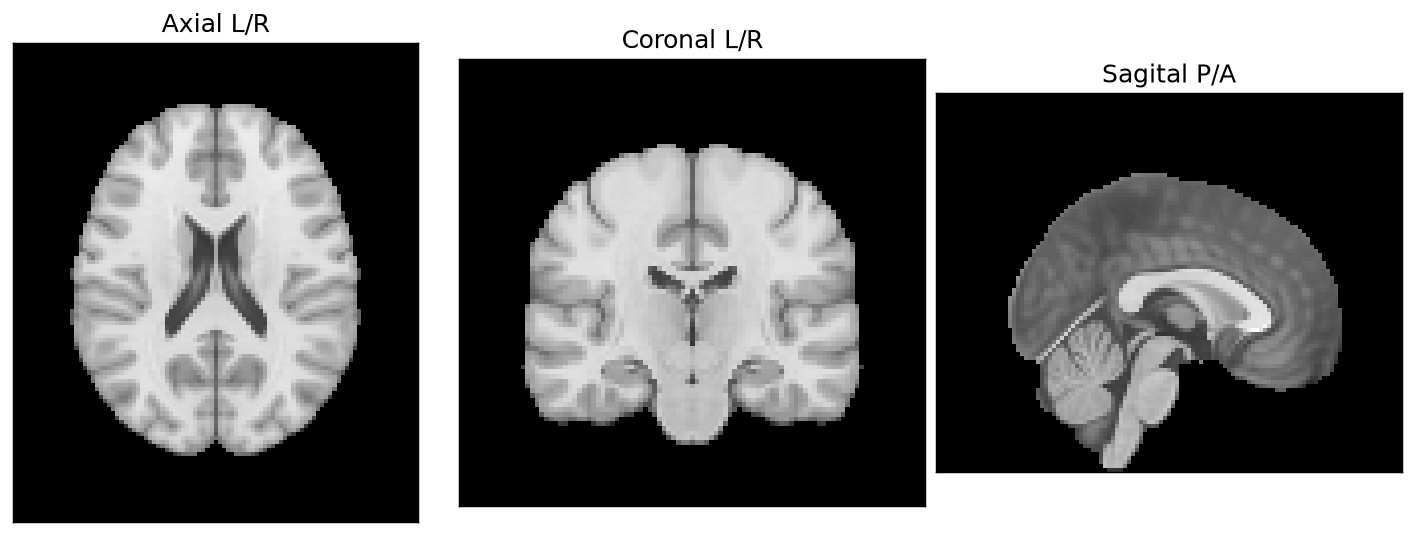

In [1]:
import sys, subprocess, importlib.util
if importlib.util.find_spec("nilearn") is None or importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nilearn==0.12.1", "matplotlib>=3.8,<4"])
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
ruta = Path("datos/mni152_2mm.nii.gz")
if ruta.exists():
    imagen = nib.load(ruta)
else:
    from nilearn.datasets import load_mni152_template
    imagen = load_mni152_template(resolution=2)
imagen = nib.as_closest_canonical(imagen)
datos = imagen.get_fdata(dtype=np.float32)
fig, ax = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
for panel, matriz, titulo in zip(ax, [datos[:,:,46].T, datos[:,57,:].T, datos[49,:,:].T], ["Axial L/R", "Coronal L/R", "Sagital P/A"]):
    panel.imshow(matriz, cmap="gray", origin="lower", vmin=0, vmax=1)
    panel.set(title=titulo, xticks=[], yticks=[])
plt.show()



**El código línea por línea**

1. Herramientas para comprobar e instalar las bibliotecas en este mismo Python.
2. Instala solo si falta Nilearn o Matplotlib.
3. Descarga las bibliotecas; sus dependencias incluyen NumPy, NiBabel y SciPy.
4. Path representa rutas de archivos de forma portable.
5. NumPy permite guardar y calcular con matrices de números; usaremos el nombre corto np.
6. Matplotlib dibuja las imágenes y gráficas; usaremos el nombre corto plt.
7. NiBabel abre volúmenes NIfTI; usaremos el nombre corto nib.
8. Busca la copia de la plantilla dentro de la carpeta datos del proyecto.
9. Elige la ruta local cuando el proyecto incluye los datos.
10. Abre el archivo NIfTI público con NiBabel sin cargar dependencias de aprendizaje automático.
11. Solo recurre a Nilearn cuando falta la copia local.
12. Importa el cargador de la plantilla incluida en Nilearn.
13. Obtiene esa plantilla con resolución documentada de 2 mm.
14. Reordena los ejes hacia RAS+ conservando su geometría; no elimina toda posible oblicuidad.
15. Extrae los números del volumen como decimales de 32 bits.
16. Crea una figura con tres paneles en una fila.
17. Empareja paneles, cortes y títulos; dos puntos selecciona todos los índices y T intercambia filas y columnas.
18. Muestra cada corte con el origen abajo y la misma escala de gris de 0 a 1.
19. Escribe títulos y orientación horizontal; los ejes físicos aparecerán en la lección 5.
20. Presenta la figura en la salida del cuaderno.

**Observa:** las vistas son cortes de un volumen, no tres personas. **L/R** significan izquierda/derecha; **P/A**, posterior/anterior; **I/S**, inferior/superior. Aquí la izquierda aparece a la izquierda en axial y coronal.

**Cambia:** compara los tres planos y localiza cómo cambia la silueta cerebral. **Pregunta:** ¿esta imagen nos dice si alguien está enfermo? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no. Es una plantilla promedio de referencia, útil para aprender a representar datos.

</details>



### Celdas, salidas y variables
No necesitas conocimientos de medicina ni programación previa. Una **celda de código** contiene instrucciones que se ejecutan; una **salida** muestra sus resultados; una **variable** es un nombre que guarda un valor. Ejecuta en orden, pues las celdas siguientes reutilizan variables anteriores. Si cambias una celda, vuelve a ejecutar las que dependen de ella.


**Entorno:** Google Colab o Jupyter con Python. En Colab sube el cuaderno; no necesitas montar Drive ni GPU. Para trabajar localmente sin internet, prepara primero las bibliotecas de `requirements.txt` y conserva `datos/` junto al cuaderno. No subas información de pacientes a Colab ni a herramientas de IA.

## 2 Una imagen pequeña es una tabla de números
Empecemos con una imagen de **6 filas por 6 columnas**. Un **píxel** es una casilla: su valor determina el gris. Usaremos 0 para negro y 5 para blanco; los valores intermedios producen grises. Esta escala es un ejemplo, no una regla universal. Los índices de Python empiezan en 0. `np.array` reúne las filas; `imshow` transforma la tabla en una imagen.

**El código línea por línea**

1. Construye una matriz decimal de 6 por 6; cada lista interior es una fila.
2. Reserva espacio para una sola imagen.
3. Convierte 0 a negro y 5 a blanco; nearest mantiene visibles las casillas.
4. Recorre las filas 0, 1, 2, 3, 4 y 5.
5. En cada fila recorre sus seis columnas.
6. Escribe el número en el centro de su píxel.
7. Identifica los ejes como índices, no milímetros.
8. Muestra números y grises en la misma figura.

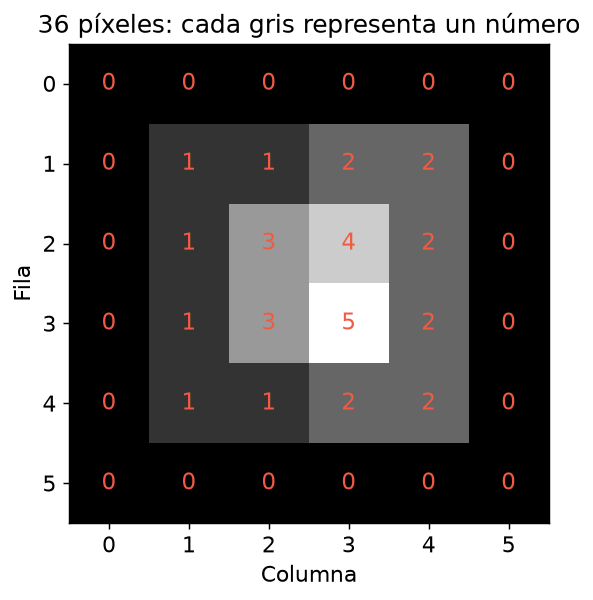

In [2]:
juguete = np.array([[0,0,0,0,0,0], [0,1,1,2,2,0], [0,1,3,4,2,0], [0,1,3,5,2,0], [0,1,1,2,2,0], [0,0,0,0,0,0]], dtype=float)
fig, ax = plt.subplots(figsize=(5, 4.5), layout="constrained")
ax.imshow(juguete, cmap="gray", vmin=0, vmax=5, interpolation="nearest")
for fila in range(6):
    for columna in range(6):
        ax.text(columna, fila, int(juguete[fila, columna]), ha="center", va="center", color="#f25b42", fontsize=13)
ax.set(title="36 píxeles: cada gris representa un número", xlabel="Columna", ylabel="Fila", xticks=range(6), yticks=range(6))
plt.show()

**Observa:** el 5 es más claro que el 1. Las casillas negras también son datos: contienen cero. **Cambia:** recorre con la vista una fila y lee sus seis valores. **Pregunta:** ¿cuántos píxeles tiene la imagen? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

6 × 6 = 36; no 6 + 6.

</details>



## 3 Leer y cambiar un píxel
Los corchetes seleccionan una posición: `juguete[fila, columna]`. Así, `[2, 3]` es la tercera fila y la cuarta columna. Un signo `=` guarda un resultado; `==` compara. Usaremos `.copy()` para crear otra matriz y preservar el original. Esta distinción será importante al filtrar una imagen médica.

**El código línea por línea**

1. Guarda el índice de fila que vamos a consultar.
2. Guarda el índice de columna; los índices empiezan en cero.
3. Lee el valor 4 de la casilla elegida.
4. Crea una matriz independiente del original.
5. Cambia una sola casilla de la copia a negro.
6. Crea dos paneles para comparar.
7. Recorre ambas matrices con sus nombres.
8. Usa exactamente la misma escala de grises en ambas.
9. Describe cada imagen y sus índices.
10. Presenta la comparación.
11. Comprueba que la primera matriz no cambió.

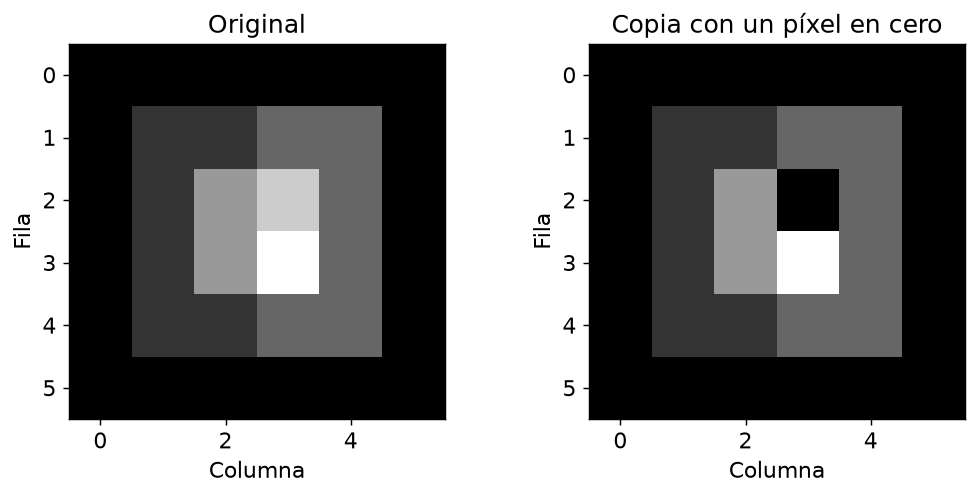

Valor original: 4.0
El original sigue valiendo: 4.0


In [3]:
fila = 2
columna = 3
print("Valor original:", juguete[fila, columna])
modificada = juguete.copy()
modificada[fila, columna] = 0
fig, ax = plt.subplots(1, 2, figsize=(8, 3.7), layout="constrained")
for panel, matriz, titulo in zip(ax, [juguete, modificada], ["Original", "Copia con un píxel en cero"]):
    panel.imshow(matriz, cmap="gray", vmin=0, vmax=5, interpolation="nearest")
    panel.set(title=titulo, xlabel="Columna", ylabel="Fila")
plt.show()
print("El original sigue valiendo:", juguete[fila, columna])

**Observa:** modificar una casilla cambia un lugar de la imagen. **Cambia:** prueba `fila = 3`, `columna = 3` y vuelve a ejecutar esta celda. Luego restaura 2 y 3.

**Ejercicio 1:** predice qué valor leerías en `[3, 3]` antes de ejecutar y explica por qué usamos una copia. 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

5; la copia permite experimentar sin modificar el original. Una misma operación podría cambiar millones de valores en una imagen grande.

</details>



## 4 Del píxel al volumen y los milímetros
Una resonancia 3D apila casillas con volumen, llamadas **vóxeles**. El archivo **NIfTI** reúne valores y geometría. `shape` cuenta vóxeles por eje; `get_zooms()` da su tamaño físico. La matriz **affine** traduce índices `(i, j, k)` a coordenadas `(x, y, z)`.

**RAS+** significa que al aumentar x vamos hacia la derecha, al aumentar y hacia anterior y al aumentar z hacia superior. Esto no establece dónde está una lesión. La copia suministrada declara mm; la plantilla original de Nilearn puede declarar `unknown`. En este caso concreto sabemos por su documentación que la resolución es mm. Nunca deduzcas esa unidad para un archivo desconocido.

**El código línea por línea**

1. Cuenta los vóxeles del volumen en sus tres ejes.
2. Lee los tres tamaños de vóxel, documentados en milímetros para esta plantilla.
3. Guarda la transformación de índices a coordenadas físicas.
4. Obtiene las letras de orientación de los ejes.
5. Detiene el cuaderno si esta imagen no está orientada como esperamos.
6. Comprueba que esta plantilla es ortogonal y tiene pasos positivos; nuestro visor no cubre imágenes oblicuas.
7. Calcula la coordenada x del centro de cada columna.
8. Calcula la coordenada y del centro de cada fila axial.
9. Calcula la coordenada z del centro de cada corte axial.
10. Usa los bordes exteriores de los píxeles, medio paso más allá de sus centros.
11. Resume cantidad, tamaño y orientación sin confundirlos.
12. Muestra la transformación y un ejemplo concreto.

In [4]:
forma = datos.shape
pasos = np.array(imagen.header.get_zooms()[:3])
affine = imagen.affine
orientacion = nib.aff2axcodes(affine)
assert orientacion == ("R", "A", "S")
assert np.allclose(affine[:3, :3], np.diag(pasos))
x = affine[0, 3] + pasos[0] * np.arange(forma[0])
y = affine[1, 3] + pasos[1] * np.arange(forma[1])
z = affine[2, 3] + pasos[2] * np.arange(forma[2])
extension = [x[0]-pasos[0]/2, x[-1]+pasos[0]/2, y[0]-pasos[1]/2, y[-1]+pasos[1]/2]
print("Forma:", forma, "| tamaño de voxel en mm:", pasos, "| orientación:", orientacion)
print("Affine:\n", affine, "\nÍndice (49,57,46) en mm:", nib.affines.apply_affine(affine, [49,57,46]))

Forma: (99, 117, 95) | tamaño de voxel en mm: [2. 2. 2.] | orientación: ('R', 'A', 'S')
Affine:
 [[   2.    0.    0.  -98.]
 [   0.    2.    0. -134.]
 [   0.    0.    2.  -72.]
 [   0.    0.    0.    1.]] 
Índice (49,57,46) en mm: [  0. -20.  20.]


**Observa:** la forma es `(99, 117, 95)` y cada vóxel mide `(2, 2, 2)` mm. Son **cantidades** y **tamaños**, respectivamente. El índice `(49, 57, 46)` está en `(0, −20, 20)` mm. **Cambia:** solo sobre papel: calcula el desplazamiento de 10 pasos en k. **Pregunta:** ¿son 10 mm? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no, son 10 × 2 = 20 mm en esta plantilla. La affine completa es necesaria para imágenes con geometría diferente.

</details>



## 5 Tres cortes con orientación física
`:` significa «todos los índices» de ese eje. `datos[:, :, k]` conserva x e y y fija z: es axial. `datos[:, j, :]` fija y: es coronal. `datos[i, :, :]` fija x: es sagital. `.T` intercambia filas y columnas para dibujar los ejes en la posición que hemos explicado. `origin="lower"` coloca el origen de la matriz mostrada abajo. `extent` conecta los bordes de la imagen con milímetros.

**El código línea por línea**

1. Elige un punto para mostrar cortes axial, coronal y sagital.
2. Crea las tres matrices 2D sin modificar el volumen.
3. Declara los bordes en mm; 1 mm es medio vóxel de esta plantilla.
4. Escribe la posición física fija de cada plano.
5. Nombra el eje horizontal y vertical de cada plano.
6. Abre tres paneles con espacio para las unidades.
7. Reúne los datos de cada vista en un mismo recorrido.
8. Mantiene la proporción física y la escala de intensidad.
9. Añade posición y orientación comprobables.
10. Muestra los tres cortes en sus coordenadas físicas.

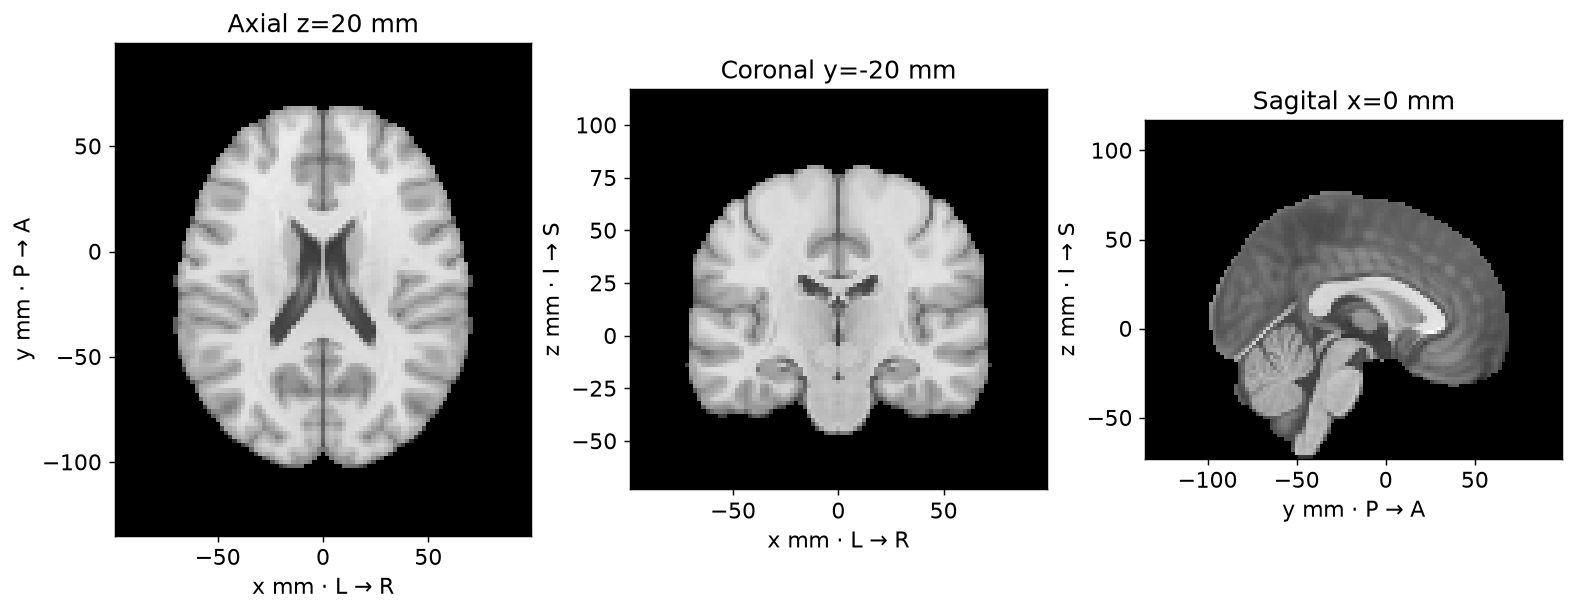

In [5]:
i, j, k = 49, 57, 46
cortes = [datos[:, :, k].T, datos[:, j, :].T, datos[i, :, :].T]
extensiones = [extension, [x[0]-1,x[-1]+1,z[0]-1,z[-1]+1], [y[0]-1,y[-1]+1,z[0]-1,z[-1]+1]]
titulos = [f"Axial z={z[k]:.0f} mm", f"Coronal y={y[j]:.0f} mm", f"Sagital x={x[i]:.0f} mm"]
etiquetas = [("x mm · L → R", "y mm · P → A"), ("x mm · L → R", "z mm · I → S"), ("y mm · P → A", "z mm · I → S")]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.6), layout="constrained")
for panel, corte_local, limites, titulo, etiqueta in zip(ax, cortes, extensiones, titulos, etiquetas):
    panel.imshow(corte_local, cmap="gray", origin="lower", extent=limites, vmin=0, vmax=1, aspect="equal")
    panel.set(title=titulo, xlabel=etiqueta[0], ylabel=etiqueta[1])
plt.show()

**Observa:** las escalas están en milímetros; no son números de fila. Las flechas indican el sentido positivo del eje. **Cambia:** compara la vista sagital con la galería inicial. **Pregunta:** ¿por qué no usamos el mismo par de ejes en todos los paneles? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

cada plano conserva dos ejes y fija el tercero.

</details>



## 6 Mover un corte
Cambiar `k` elige otra lámina del mismo volumen. No cambia el tamaño de los vóxeles. `assert` verifica que el índice está permitido y muestra un error si no lo está. Compararemos el corte de referencia k=46 con una elección editable.

**El código línea por línea**

1. Cambia este entero entre 0 y 94; con 56 veremos un plano 20 mm más superior.
2. Comprueba el rango antes de extraer el corte.
3. Crea dos paneles con idéntico tamaño.
4. Compara la referencia con el índice elegido.
5. Dibuja cada corte con la misma escala y orientación.
6. Relaciona explícitamente índice y milímetros.
7. Presenta el cambio de posición.
8. Resta las coordenadas para medir cuánto nos movimos.

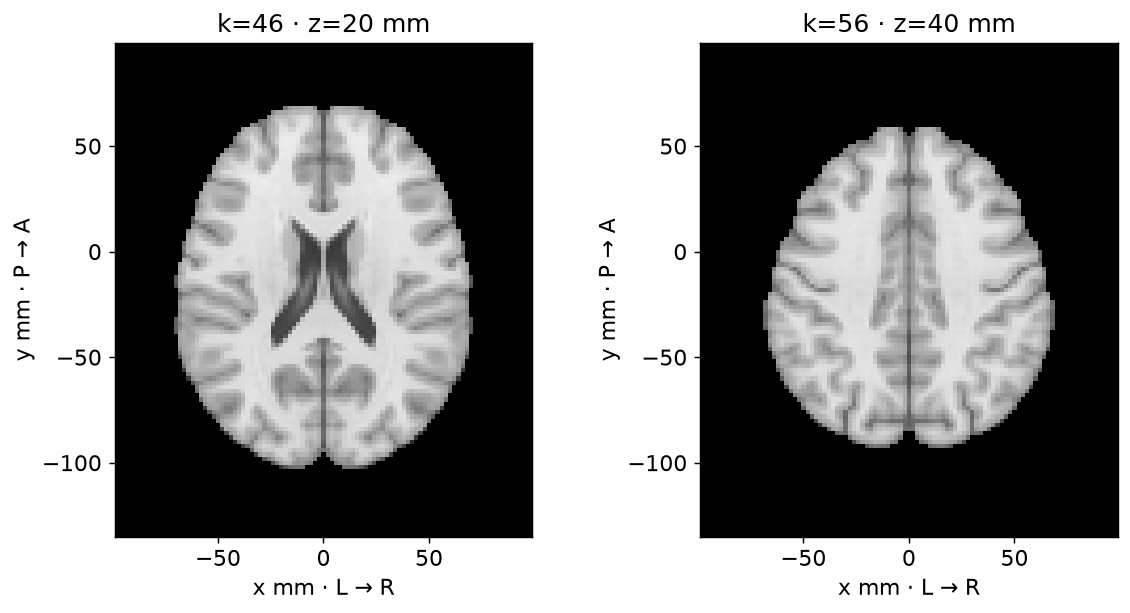

Desplazamiento en z: 20.0 mm


In [6]:
k_nuevo = 56
assert 0 <= k_nuevo < forma[2]
fig, ax = plt.subplots(1, 2, figsize=(9, 4.6), layout="constrained")
for panel, indice in zip(ax, [46, k_nuevo]):
    panel.imshow(datos[:, :, indice].T, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=f"k={indice} · z={z[indice]:.0f} mm", xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("Desplazamiento en z:", z[k_nuevo] - z[46], "mm")

**Observa:** se modifica qué parte del volumen vemos, no la intensidad de los datos. **Cambia:** prueba k=36, 46 y 56. Después deja 56; las siguientes lecciones usan expresamente k=46 para ser comparables.

**Ejercicio 2:** explica por qué k=56 está 20 mm más arriba que k=46 y qué se conserva. 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

diez pasos de 2 mm; se conservan x, y y el tamaño de vóxel. El contenido del plano puede ser distinto porque su posición cambió.

</details>



## 7 Cambiar el contraste sin cambiar los datos
Desde aquí trabajaremos con **el mismo corte axial k=46, z=20 mm**. `vmin` indica qué intensidad se dibuja negra y `vmax` cuál se dibuja blanca. Lo que queda fuera se muestra saturado. Esta ventana cambia la visualización, no los valores de la matriz. La intensidad de esta plantilla está reescalada; no son unidades Hounsfield ni probabilidades.

**El código línea por línea**

1. Guarda una copia 2D del corte de referencia para las próximas operaciones.
2. Define tres pares de negro y blanco, de ventana amplia a estrecha.
3. Reserva tres paneles para los mismos datos.
4. Recorre las tres ventanas sin cambiar corte.
5. Cambia solo cómo se asignan números a grises.
6. Muestra los límites elegidos y la orientación.
7. Permite comparar contraste y saturación.
8. Verifica que la visualización no modificó el corte.

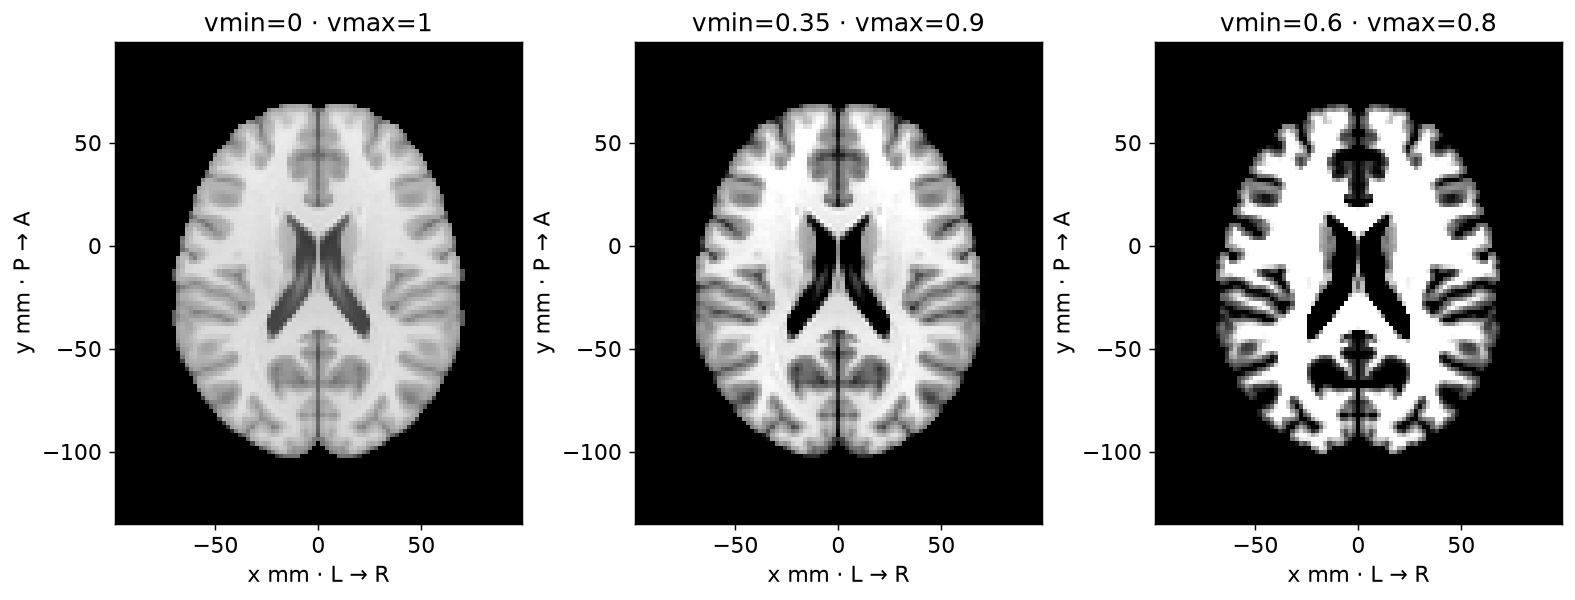

Los datos siguen siendo los mismos: True


In [7]:
corte = datos[:, :, 46].T.copy()
ventanas = [(0, 1), (0.35, 0.9), (0.6, 0.8)]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.5), layout="constrained")
for panel, ventana in zip(ax, ventanas):
    panel.imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=ventana[0], vmax=ventana[1])
    panel.set(title=f"vmin={ventana[0]} · vmax={ventana[1]}", xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("Los datos siguen siendo los mismos:", np.array_equal(corte, datos[:, :, 46].T))

**Observa:** una ventana estrecha realza unas diferencias y oculta otras por saturación. **Cambia:** reemplaza la última ventana por `(0.4, 0.85)` y compara; después restaura `(0.6, 0.8)`. **Pregunta:** ¿apareció tejido nuevo? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no; el mismo conjunto de números recibió otro mapa de grises.

</details>



## 8 Construir un histograma contando píxeles
Un **histograma** cuenta cuántos valores caen en cada intervalo. El eje horizontal es **intensidad**, no posición; el vertical es **cantidad de píxeles**. Primero contaremos los seis valores exactos del juguete. `.ravel()` convierte la matriz en una lista de 36 números. `np.histogram` cuenta; `bar` dibuja barras ya contadas.

**El código línea por línea**

1. Reúne los 36 números en una lista, sin importar dónde estaban sus píxeles.
2. Crea intervalos centrados en los valores enteros 0 a 5.
3. Cuenta los valores dentro de cada intervalo y devuelve sus límites.
4. Abre un panel para las barras.
5. Dibuja una barra por intensidad con altura igual al conteo.
6. Recorre intensidades y conteos juntos.
7. Escribe el conteo sobre cada barra.
8. Etiqueta ejes y deja espacio sobre la barra mayor.
9. Muestra el resumen numérico de la imagen.
10. Comprueba que los conteos suman los 36 píxeles.

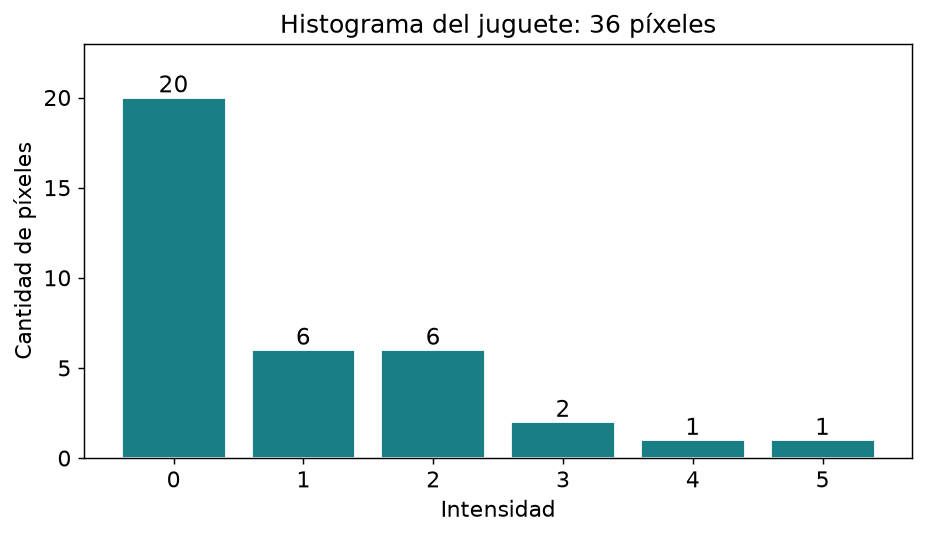

Conteos de 0 a 5: [20  6  6  2  1  1] | suma: 36


In [8]:
valores_juguete = juguete.ravel()
limites_juguete = np.arange(-0.5, 6.5, 1)
conteos, limites = np.histogram(valores_juguete, bins=limites_juguete)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.bar(np.arange(6), conteos, color="#197f85", edgecolor="white")
for intensidad, cantidad in zip(np.arange(6), conteos):
    ax.text(intensidad, cantidad + 0.3, str(cantidad), ha="center")
ax.set(title="Histograma del juguete: 36 píxeles", xlabel="Intensidad", ylabel="Cantidad de píxeles", xticks=range(6), ylim=(0,23))
plt.show()
print("Conteos de 0 a 5:", conteos, "| suma:", conteos.sum())

**Observa:** los conteos son 20, 6, 6, 2, 1 y 1. El fondo cero está incluido aquí para aprender a contar. **Cambia:** sin modificar el código, imagina intercambiar dos casillas. **Pregunta:** ¿cambiaría el histograma? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no, si conserva los mismos números. El histograma pierde la información de dónde está cada píxel.

</details>



## 9 Leer el histograma de una resonancia
En la resonancia hay muchos valores distintos. **Bins** son intervalos: con 20 bins dividimos un rango en 20 grupos. Para que el fondo no domine, seleccionaremos los píxeles del corte con `corte > 0.000001`. El pequeño valor evita incluir residuos numéricos casi cero del remuestreo. Esto es una **regla de selección educativa**, no una máscara cerebral validada.

Los histogramas de las lecciones 9–11 usan siempre ese mismo soporte del **corte**, no el volumen entero. `hist` realiza el conteo y el dibujo. Los bins son intervalos cerrados a izquierda y abiertos a derecha, excepto el último, que incluye su extremo final.

**El código línea por línea**

1. Selecciona píxeles por encima de 0.000001; crea una matriz de verdadero o falso.
2. Extrae únicamente las intensidades de las casillas seleccionadas.
3. Crea un gráfico de tamaño cómodo para leer los ejes.
4. Cuenta las intensidades en 20 intervalos del rango 0 a 1.
5. Evita confundir intensidad con coordenada espacial.
6. Presenta la distribución de intensidades.
7. Explicita qué se contó y qué se dejó fuera.

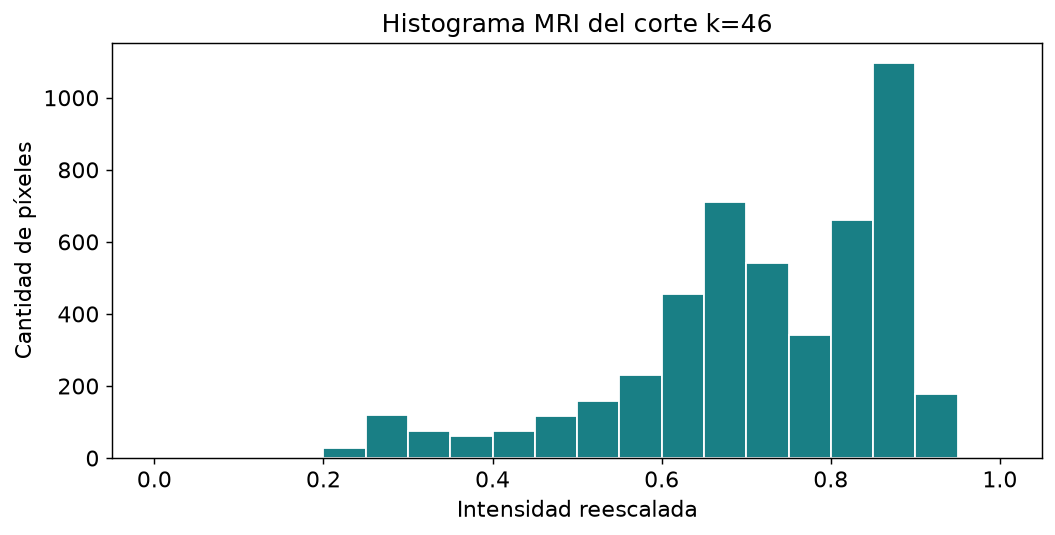

Píxeles del corte: 11583 | analizados: 4859 | excluidos: 6724


In [9]:
soporte = corte > 1e-6
valores = corte[soporte]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.hist(valores, bins=20, range=(0, 1), color="#197f85", edgecolor="white")
ax.set(title="Histograma MRI del corte k=46", xlabel="Intensidad reescalada", ylabel="Cantidad de píxeles")
plt.show()
print("Píxeles del corte:", corte.size, "| analizados:", valores.size, "| excluidos:", corte.size-valores.size)

**Observa:** una barra alta indica muchos píxeles dentro de un intervalo, no una lesión. **Cambia:** piensa qué sucedería si incluyéramos todos los ceros del fondo. **Pregunta:** ¿aparecería una barra grande cerca de cero? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

sí; por eso declaramos el soporte y no ocultamos cómo se seleccionó.

</details>



## 10 Comparar veinte y ochenta intervalos
Con más bins vemos más detalle, pero cada barra agrupa menos valores. Para comparar con honestidad conservaremos **los mismos valores, el mismo rango y el mismo límite vertical**. Cambiar el número de bins no cambia la imagen ni crea nuevos datos.

**El código línea por línea**

1. Cuenta primero los bins amplios para obtener una referencia vertical.
2. Cuenta los bins estrechos sobre exactamente los mismos valores.
3. Elige un límite vertical común que permite ver todas las barras.
4. Abre dos histogramas uno junto al otro.
5. Repite el dibujo con 20 y 80 intervalos.
6. Modifica solo la agrupación del histograma.
7. Mantiene iguales rango horizontal y escala vertical.
8. Muestra que una misma distribución puede verse más lisa o dentada.

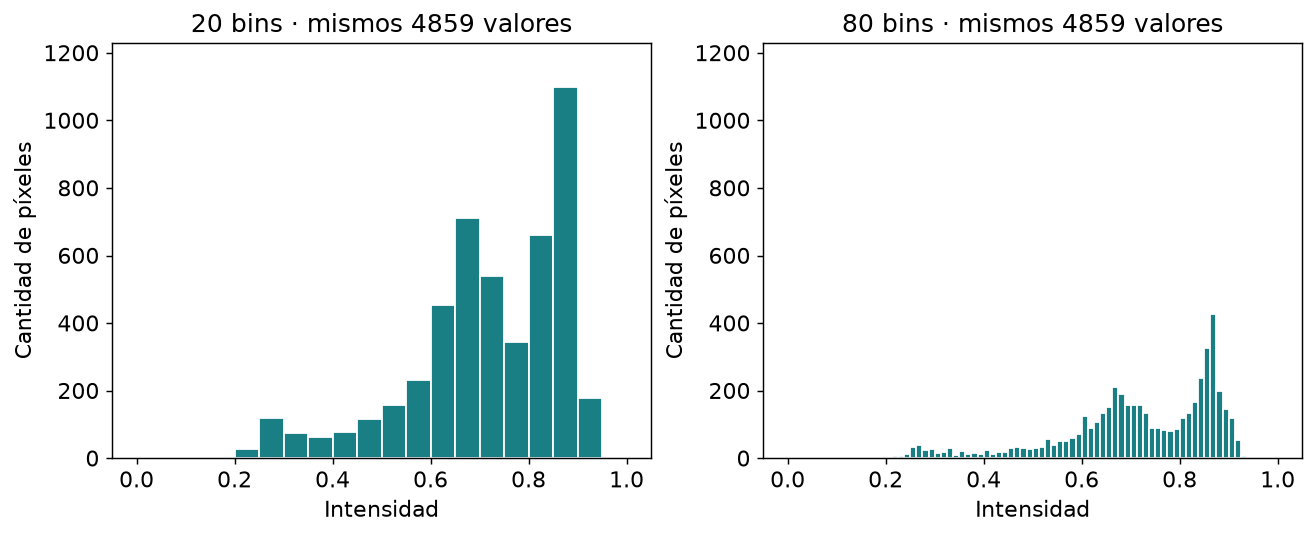

In [10]:
cuentas20, _ = np.histogram(valores, bins=20, range=(0, 1))
cuentas80, _ = np.histogram(valores, bins=80, range=(0, 1))
tope = 1.12 * max(cuentas20.max(), cuentas80.max())
fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for panel, numero_bins in zip(ax, [20, 80]):
    panel.hist(valores, bins=numero_bins, range=(0, 1), color="#197f85", edgecolor="white")
    panel.set(title=f"{numero_bins} bins · mismos {valores.size} valores", xlabel="Intensidad", ylabel="Cantidad de píxeles", ylim=(0,tope))
plt.show()

**Observa:** los picos finos pueden depender del muestreo y la cuantización de los valores. No interpretes cada barra como un tipo de tejido. **Cambia:** prueba 40 en lugar de 80, conservando el rango; después vuelve a 80.

**Ejercicio 3:** explica qué cambió y qué no cambió entre los gráficos. 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

cambió el ancho de los intervalos y, por tanto, la altura de las barras. Permanecieron la imagen, el soporte, el total de valores y el rango. La suma de los conteos sigue siendo la misma.

</details>



## 11 De un percentil a una máscara por umbral
El **percentil 90** es un valor situado cerca del punto donde queda el 90% de las intensidades por debajo. Usarlo como umbral selecciona aproximadamente el 10% superior; los empates y `>=` pueden cambiar ligeramente ese porcentaje. Una **máscara** es una matriz booleana: cada casilla se selecciona o no.

Mostraremos el histograma con una línea en el umbral y la máscara resultante. El porcentaje se calcula sobre `valores.size`, es decir, los píxeles del corte que cumplen `corte > 0.000001`. No es un porcentaje de enfermedad ni de un tejido identificado.

**El código línea por línea**

1. Cambia este número a 50 o 75 para probar un umbral diferente.
2. Comprueba que el percentil esté en su rango válido.
3. Busca el valor de intensidad correspondiente al percentil elegido.
4. Selecciona las casillas del soporte cuya intensidad alcanza o supera el umbral.
5. Calcula el porcentaje sobre el soporte declarado, no sobre toda la imagen.
6. Prepara un histograma y una imagen binaria.
7. Dibuja las intensidades usadas para elegir el umbral.
8. Señala el umbral como una posición en el eje de intensidad.
9. Muestra la etiqueta del umbral.
10. Distingue el gráfico de intensidades de la imagen espacial.
11. Dibuja seleccionado en blanco y no seleccionado en negro.
12. Explicita el denominador y la orientación.
13. Presenta la relación entre umbral numérico y selección espacial.
14. Conserva los conteos para una revisión reproducible.

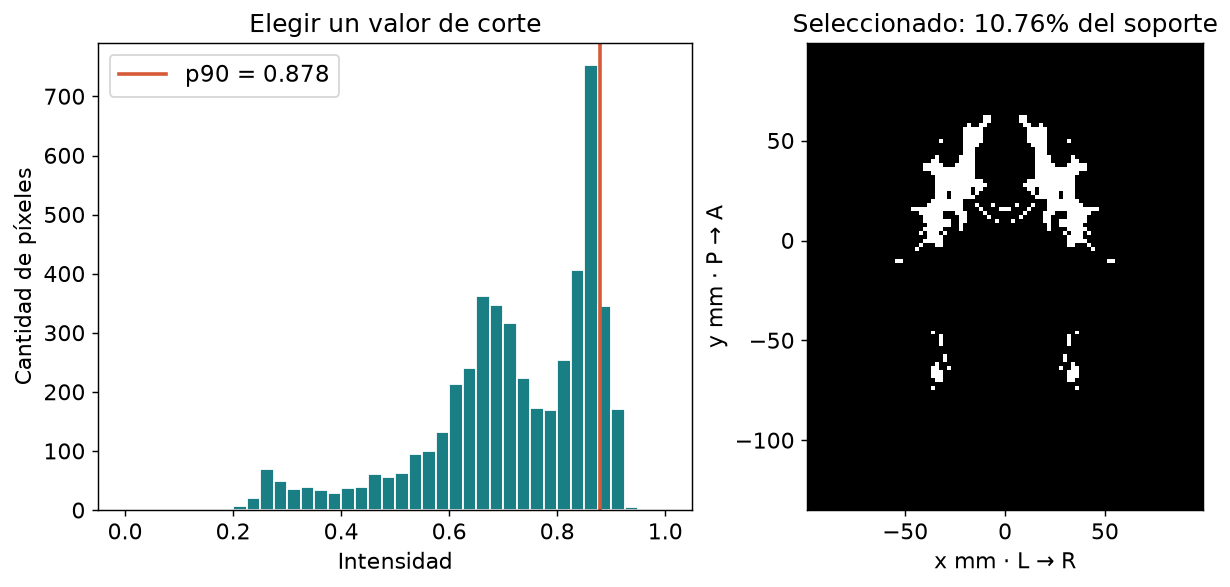

Umbral: 0.878431 | seleccionados: 523 | denominador: 4859


In [11]:
percentil = 90
assert 0 <= percentil <= 100
umbral = np.percentile(valores, percentil)
mascara = soporte & (corte >= umbral)
porcentaje = 100 * mascara.sum() / valores.size
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
ax[0].hist(valores, bins=40, range=(0, 1), color="#197f85", edgecolor="white")
ax[0].axvline(umbral, color="#d65a37", linewidth=2, label=f"p{percentil} = {umbral:.3f}")
ax[0].legend()
ax[0].set(xlabel="Intensidad", ylabel="Cantidad de píxeles", title="Elegir un valor de corte")
ax[1].imshow(mascara, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1, interpolation="nearest")
ax[1].set(title=f"Seleccionado: {porcentaje:.2f}% del soporte", xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("Umbral:", round(float(umbral),6), "| seleccionados:", int(mascara.sum()), "| denominador:", valores.size)

**Observa:** el umbral solo responde a una regla de intensidad. **Cambia:** ejecuta con 90, 75 y 50, luego restaura 90. **Pregunta:** ¿qué demuestra la región blanca? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

que esos píxeles cumplen la regla, no que pertenezcan a un tumor o tejido específico. Tampoco entrenamos un modelo de Machine Learning.

</details>



## 12 Curvas de nivel en una superficie sencilla
Imagina un mapa de altura: una curva de nivel une puntos con **la misma altura**. En una imagen, une puntos con **la misma intensidad**. Para verlo sin anatomía construiremos una colina matemática. `meshgrid` coloca una coordenada x e y en cada casilla; `contour` interpola líneas entre puntos de una cuadrícula.

**El código línea por línea**

1. Crea 61 posiciones igualmente espaciadas de -3 a 3, sin unidades médicas.
2. Forma una cuadrícula con la posición horizontal y vertical de cada punto.
3. Da el valor más alto al centro y valores menores al alejarse; es una imagen artificial.
4. Elige cuatro intensidades crecientes para dibujar curvas.
5. Crea una vista del mapa artificial.
6. Sitúa los bordes medio paso fuera de los centros de la cuadrícula.
7. Une lugares de igual valor usando coordenadas de los centros.
8. Escribe el valor de intensidad de cada curva.
9. Indica que no estamos viendo coordenadas anatómicas.
10. Presenta el equivalente visual de un mapa de nivel.

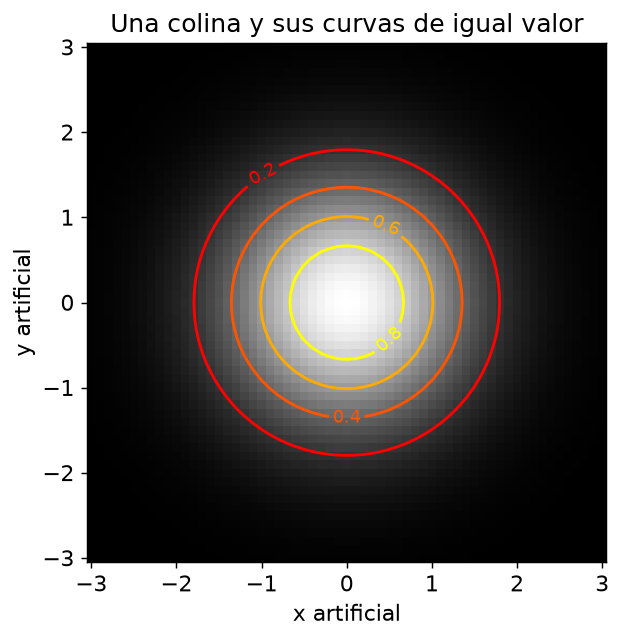

In [12]:
eje = np.linspace(-3, 3, 61)
X, Y = np.meshgrid(eje, eje)
colina = np.exp(-(X**2 + Y**2)/2)
niveles = [0.2, 0.4, 0.6, 0.8]
fig, ax = plt.subplots(figsize=(6, 4.8), layout="constrained")
ax.imshow(colina, origin="lower", extent=[-3.05,3.05,-3.05,3.05], cmap="gray", vmin=0, vmax=1)
lineas = ax.contour(eje, eje, colina, levels=niveles, cmap="autumn", linewidths=1.6)
ax.clabel(lineas, inline=True, fontsize=10, fmt="%.1f")
ax.set(title="Una colina y sus curvas de igual valor", xlabel="x artificial", ylabel="y artificial")
plt.show()

**Observa:** todas las posiciones sobre la curva 0.6 tienen el mismo nivel interpolado. **Cambia:** agrega 0.9 al final de `niveles`. **Pregunta:** ¿una curva 0.8 indica un borde más fuerte que una curva 0.2? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no; expresa una intensidad, no cuánto cambia la intensidad. Para medir cambio necesitaremos un gradiente.

</details>



## 13 Curvas de nivel sobre la resonancia
Aplicaremos la misma idea al corte MRI. Elegimos niveles explícitos de 0.4, 0.6 y 0.8. Las líneas pueden formar muchos contornos porque distintas regiones comparten intensidades. **No equivalen a fronteras anatómicas validadas.** `imshow` usa bordes de píxel, mientras `contour(x, y, ...)` usa los centros: así evitamos desalinear las curvas medio píxel.

**El código línea por línea**

1. Define intensidades crecientes de esta plantilla reescalada.
2. Asigna un color distinto a cada uno de los tres niveles.
3. Abre una imagen grande para ver las líneas.
4. Dibuja el corte con sus bordes físicos.
5. Dibuja curvas sobre centros x e y, cada nivel con un color.
6. Empareja colores e intensidades para construir una leyenda legible.
7. Crea una muestra de línea para la leyenda; las listas vacías no añaden datos a la imagen.
8. Identifica los tres colores sin implicar que representan tejidos.
9. Mantiene unidades y orientación.
10. Muestra cómo niveles numéricos se convierten en líneas.

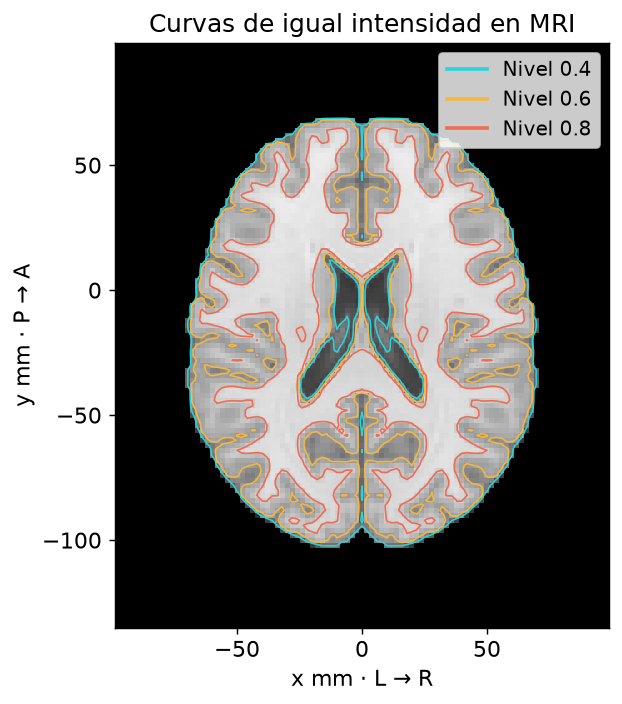

In [13]:
niveles_mri = [0.4, 0.6, 0.8]
colores_nivel = ["#29d3dc", "#f5b642", "#f06b52"]
fig, ax = plt.subplots(figsize=(6.2, 5.3), layout="constrained")
ax.imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
lineas = ax.contour(x, y, corte, levels=niveles_mri, colors=colores_nivel, linewidths=0.9)
for color, nivel_actual in zip(colores_nivel, niveles_mri):
    ax.plot([], [], color=color, linewidth=2, label=f"Nivel {nivel_actual}")
ax.legend(loc="upper right", fontsize=11)
ax.set(title="Curvas de igual intensidad en MRI", xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()

**Observa:** las curvas pueden ser numerosas y discontinuas; describen los valores de esta imagen. **Cambia:** prueba `[0.5, 0.7, 0.85]`, conservando el orden creciente; luego restaura los valores originales. **Pregunta:** ¿puedo llamar «borde de órgano» a estas líneas? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no sin un método y una validación anatómica adicionales.

</details>



## 14 Una curva no es lo mismo que una máscara
Para un mismo valor de 0.7 compararemos dos preguntas: **¿dónde se cruza este nivel?** y **¿qué píxeles alcanzan o superan este nivel?** La primera produce líneas interpoladas; la segunda una región seleccionada. Ninguna mide todavía la fuerza del cambio entre vecinos.

**El código línea por línea**

1. Fija un valor común para comparar la curva y la región seleccionada.
2. Crea una máscara booleana con una regla de intensidad.
3. Reserva un panel para líneas y otro para áreas.
4. Mantiene la imagen de fondo para las curvas.
5. Traza solamente la curva del nivel elegido.
6. Dibuja las áreas que satisfacen la desigualdad.
7. Recorre los dos conceptos para etiquetarlos.
8. Conserva las mismas coordenadas en ambos.
9. Compara una línea con una selección de píxeles.

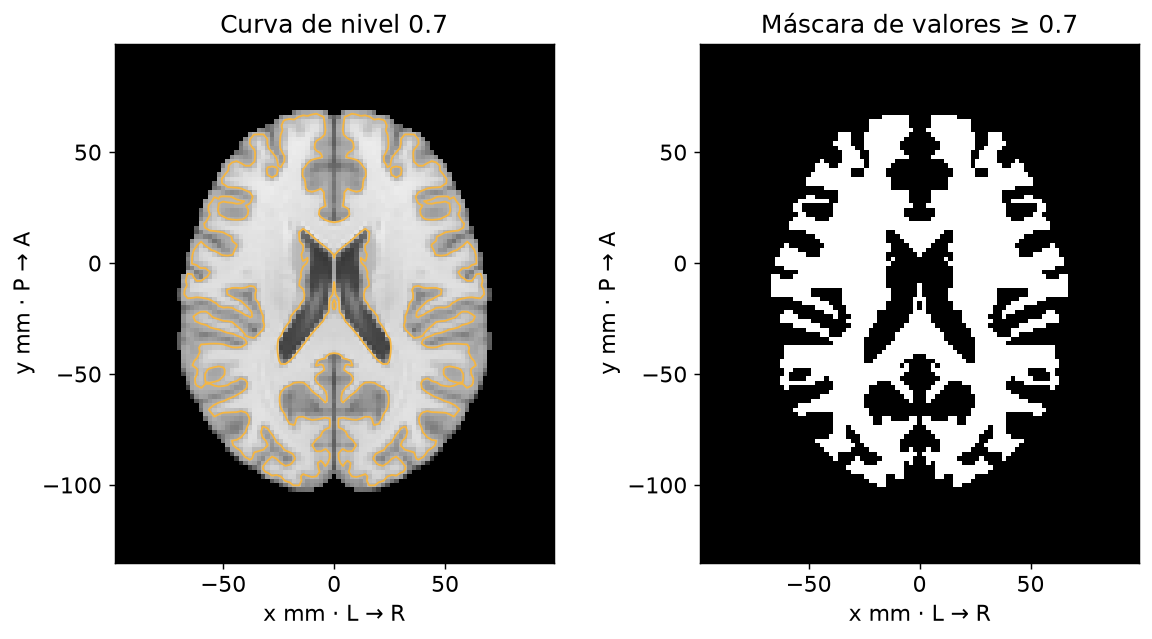

In [14]:
nivel = 0.7
region = soporte & (corte >= nivel)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.8), layout="constrained")
ax[0].imshow(corte, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
ax[0].contour(x, y, corte, levels=[nivel], colors=["#f5b642"], linewidths=1)
ax[1].imshow(region, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1, interpolation="nearest")
for panel, titulo in zip(ax, [f"Curva de nivel {nivel}", f"Máscara de valores ≥ {nivel}"]):
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()

**Observa:** una línea tiene grosor visual; la máscara llena casillas seleccionadas. **Cambia:** repite con nivel=0.8, luego restaura 0.7. **Pregunta:** ¿contorno, máscara y borde por gradiente significan lo mismo? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no. Contorno: igual intensidad; máscara: cumple una regla; gradiente: magnitud y dirección de cambio espacial.

</details>



## 15 Añadir ruido artificial de manera reproducible
Fabricaremos una perturbación aleatoria para comparar filtros. La **semilla** permite repetir los mismos números. `normal(0, 0.06, ...)` genera ruido de media cero y desviación estándar 0.06 en unidades de intensidad. **No es un modelo completo del ruido de adquisición MRI.** Sumaremos sin recortar los datos; por eso pueden quedar valores negativos o mayores que uno. La visualización sí saturará fuera de 0–1.

**El código línea por línea**

1. Guarda el punto de partida de la secuencia pseudoaleatoria.
2. Define la dispersión del ruido en unidades de intensidad, no en píxeles ni milímetros.
3. Crea un generador reproducible que no modifica el generador global.
4. Genera un número de ruido por píxel con el mismo tamaño que el corte.
5. Suma el ruido a una nueva matriz y preserva corte.
6. Abre una comparación de referencia y perturbación.
7. Usa exactamente las matrices que compararemos después.
8. Mantiene la misma ventana para no ocultar diferencias con un autoajuste.
9. Identifica referencia y simulación.
10. Muestra el efecto de la perturbación.
11. Hace visible que no recortamos los datos al intervalo de visualización.

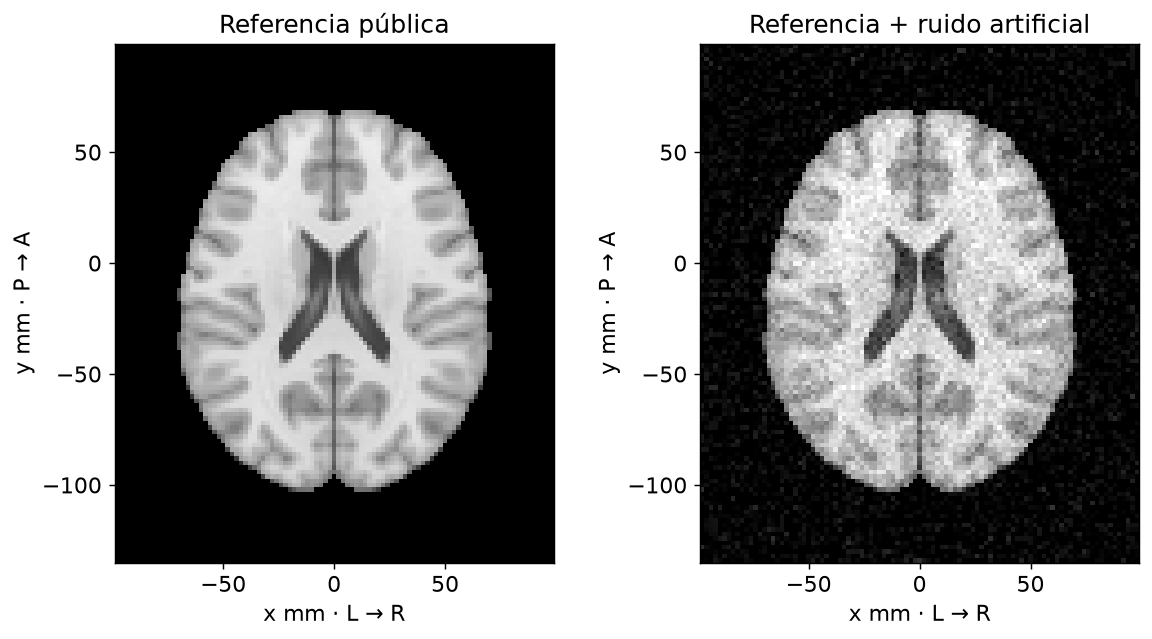

Mínimo y máximo de la matriz ruidosa: -0.239 1.11


In [15]:
semilla = 2026
sigma_ruido = 0.06
rng = np.random.default_rng(semilla)
ruido = rng.normal(0, sigma_ruido, size=corte.shape).astype(np.float32)
ruidosa = corte + ruido
fig, ax = plt.subplots(1, 2, figsize=(9, 4.8), layout="constrained")
for panel, matriz, titulo in zip(ax, [corte, ruidosa], ["Referencia pública", "Referencia + ruido artificial"]):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("Mínimo y máximo de la matriz ruidosa:", round(float(ruidosa.min()),3), round(float(ruidosa.max()),3))

**Observa:** el ruido se añade también al fondo. **Cambia:** prueba `sigma_ruido = 0.12`, ejecuta y vuelve a 0.06; vuelve a ejecutar también las lecciones de filtros que dependen de `ruidosa`. **Pregunta:** ¿qué permite la semilla? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

comparar métodos con la misma perturbación, en lugar de cambiar el problema en cada intento.

</details>



## 16 Suavizar con un filtro gaussiano
Un filtro gaussiano combina vecinos, dando más peso a los cercanos. Su parámetro **sigma** expresa la anchura espacial del filtro, en **píxeles por eje**. No es el `sigma_ruido` anterior, que medía intensidad. Con píxeles de 2 mm, sigma=1.2 píxeles equivale a **2.4 mm de desviación estándar**, no a una resolución nueva ni a FWHM.

`mode="reflect"` trata el exterior de la imagen como un reflejo al operar cerca de sus bordes. Filtraremos matrices decimales para no perder fracciones por redondeo a enteros. Esto es 2D, solo en el plano; no es un suavizado del volumen completo.

**El código línea por línea**

1. Importa herramientas de procesamiento de imágenes.
2. Elige la anchura espacial del filtro; prueba después 0.6 o 2.4.
3. Limita el control del ejercicio a un intervalo razonable.
4. Promedia con pesos gaussianos sobre la misma imagen ruidosa.
5. Crea una segunda versión con suavizado más amplio para observar pérdida de detalle.
6. Reserva una fila con ruido y dos escalas de suavizado.
7. Empareja imágenes con sus parámetros.
8. Conserva la misma ventana 0 a 1 en todos los paneles.
9. Mantiene las coordenadas del corte.
10. Permite comparar reducción de variaciones y pérdida de detalle.
11. Convierte píxeles a mm usando el tamaño comprobado de esta plantilla.

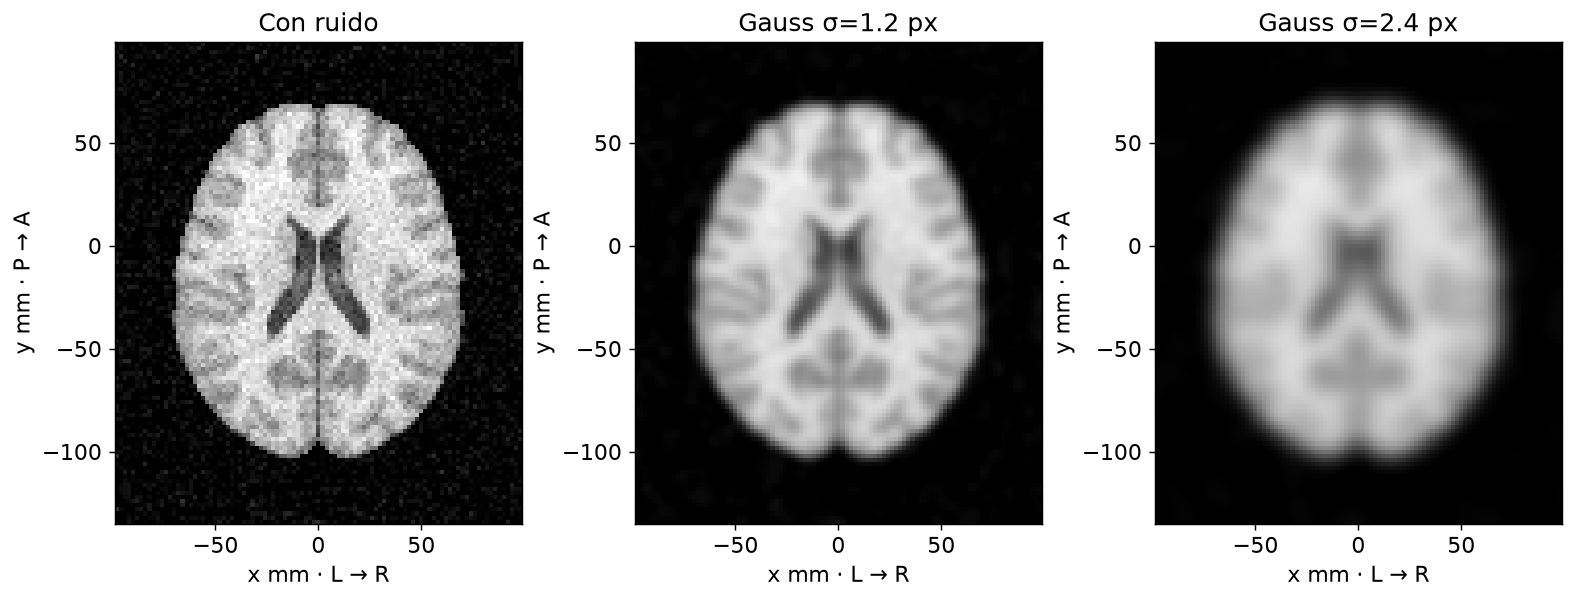

Sigma físico del primer filtro: 2.4 mm por eje del plano


In [16]:
from scipy import ndimage
sigma_pixeles = 1.2
assert 0 < sigma_pixeles <= 4
gauss = ndimage.gaussian_filter(ruidosa, sigma=sigma_pixeles, mode="reflect")
gauss_amplio = ndimage.gaussian_filter(ruidosa, sigma=2.4, mode="reflect")
fig, ax = plt.subplots(1, 3, figsize=(12, 4.5), layout="constrained")
for panel, matriz, titulo in zip(ax, [ruidosa, gauss, gauss_amplio], ["Con ruido", f"Gauss σ={sigma_pixeles} px", "Gauss σ=2.4 px"]):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("Sigma físico del primer filtro:", sigma_pixeles * pasos[0], "mm por eje del plano")

**Observa:** más suavizado elimina fluctuaciones, pero puede borrar detalle. **Cambia:** compara 0.6, 1.2 y 2.4; deja 1.2 al terminar. **Pregunta:** ¿una imagen más suave es siempre mejor? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no. Depende de la tarea y puede perder señales de interés; el aspecto agradable no valida el resultado.

</details>



## 17 Usar la mediana de una vecindad
La **mediana** ordena los valores vecinos y elige el central. Con nueve valores, es el quinto. `size=3` significa una vecindad **3 × 3** en nuestro corte 2D. En un volumen 3D significaría 3 × 3 × 3: por eso importa saber qué matriz entra al filtro. No es un promedio y no usa un sigma.

**El código línea por línea**

1. Elige un lado impar para la vecindad; usa 3 o 5 en el ejercicio.
2. Acepta solo tamaños impares pequeños para esta demostración.
3. Reemplaza cada casilla por la mediana de su vecindad sobre la misma imagen ruidosa.
4. Abre dos vistas comparables.
5. Recorre la entrada y el resultado.
6. Usa la misma escala para no exagerar el cambio.
7. Expresa el tamaño del vecindario y las coordenadas.
8. Presenta el resultado del filtro no lineal.

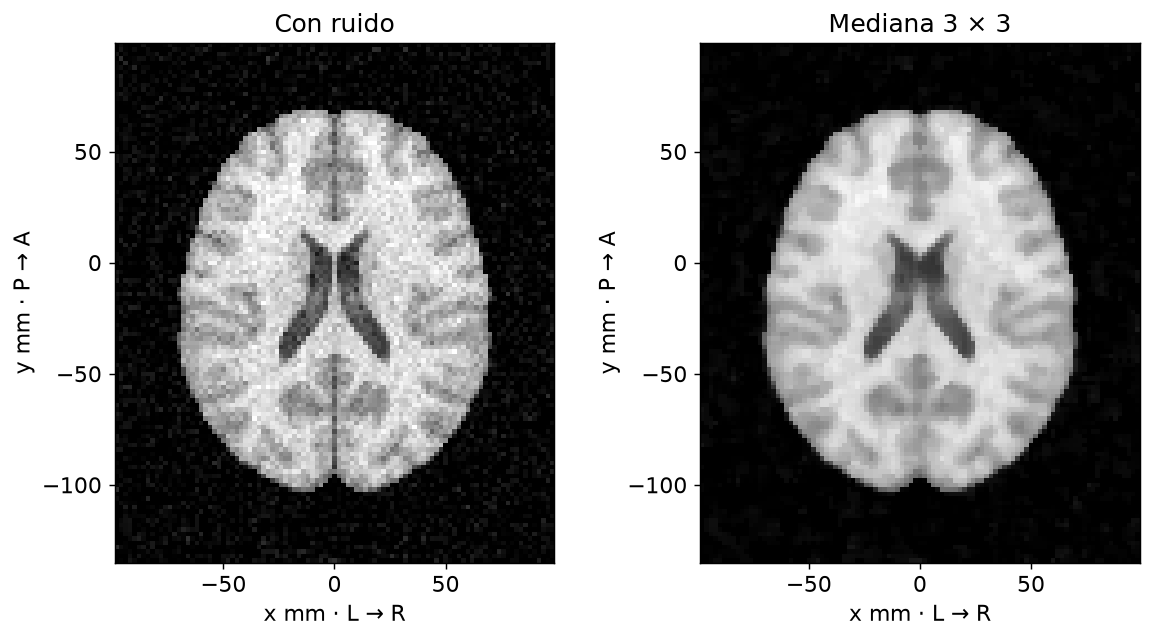

In [17]:
tamano = 3
assert tamano in [3, 5, 7]
mediana = ndimage.median_filter(ruidosa, size=tamano, mode="reflect")
fig, ax = plt.subplots(1, 2, figsize=(9, 4.8), layout="constrained")
for panel, matriz, titulo in zip(ax, [ruidosa, mediana], ["Con ruido", f"Mediana {tamano} × {tamano}"]):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()

**Observa:** la textura difiere de la gaussiana porque la operación no es la misma. **Cambia:** prueba tamaño=5 y restaura 3. **Pregunta:** en `[10,10,10,10,90,10,10,10,10]`, ¿cuáles son media y mediana? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

media 170/9 ≈ 18.89; mediana 10. Esto explica por qué responden de manera distinta a valores aislados extremos; no demuestra que uno sea mejor para toda MRI.

</details>



## 18 Comparar media, Gauss y mediana con la misma entrada
La **media local** asigna igual peso a los vecinos; Gauss favorece los cercanos; la mediana elige el valor central ordenado. Compararemos sobre **la misma matriz ruidosa** y con la **misma ventana 0–1**. La media 3 × 3 y la mediana 3 × 3 no tienen el mismo efecto que Gauss sigma=1.2: los parámetros representan operaciones distintas, no grados de suavizado equivalentes.

**El código línea por línea**

1. Promedia por igual los nueve valores de cada vecindad 3 por 3.
2. Reúne la misma entrada y los resultados obtenidos con ella.
3. Explicita parámetros para hacer la comparación reproducible.
4. Distribuye las cuatro vistas en dos filas y dos columnas.
5. Aplana solo la lista de paneles para recorrerlos de uno en uno.
6. Fija la escala común y evita normalizar por separado cada resultado.
7. Identifica la operación y mantiene orientación física.
8. Ofrece una comparación visual honesta de los filtros.

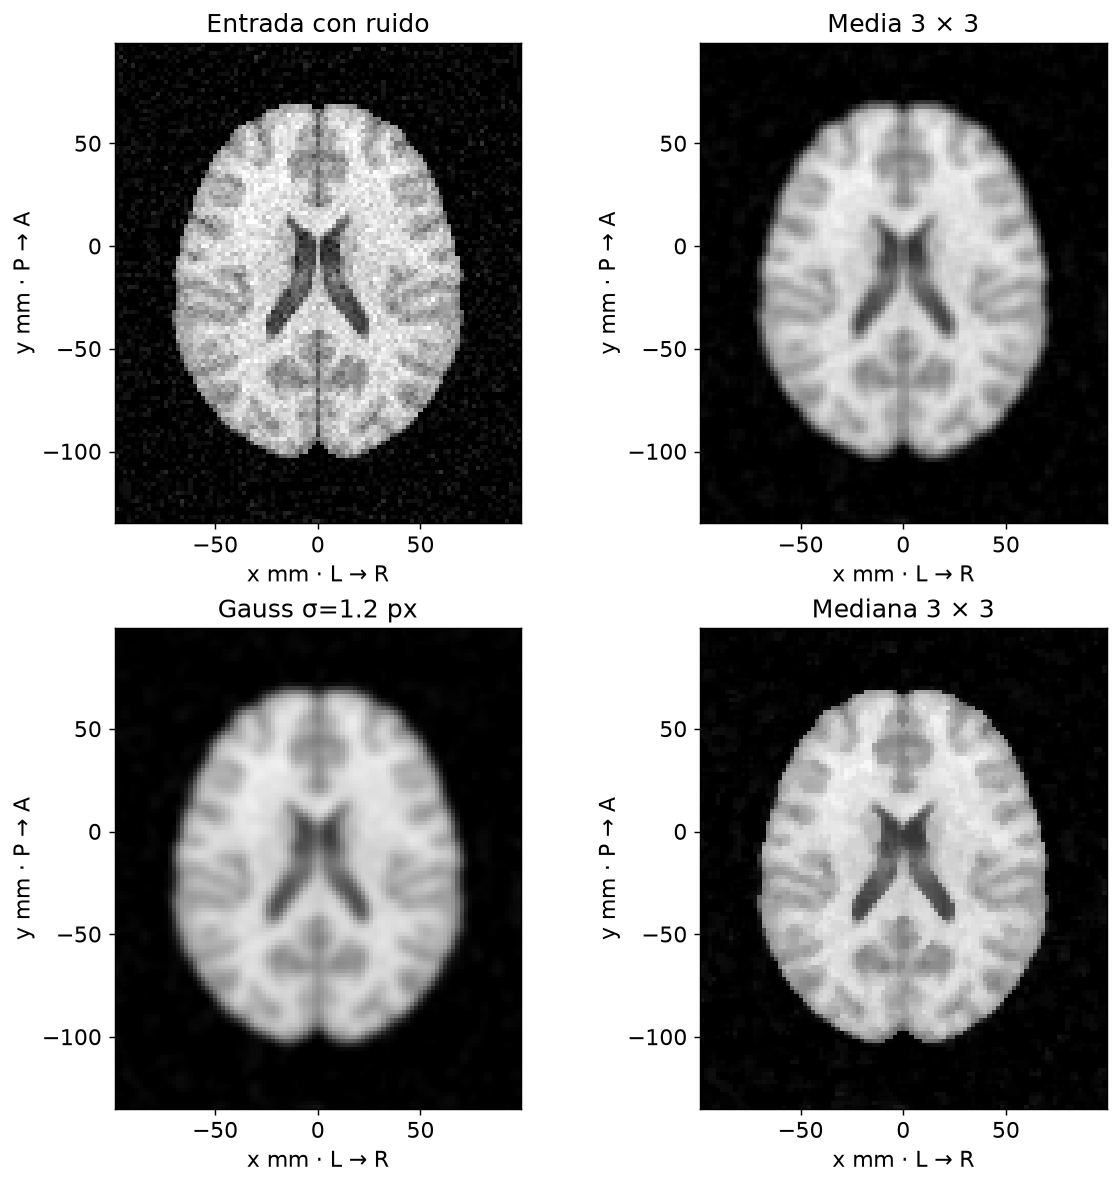

In [18]:
media = ndimage.uniform_filter(ruidosa, size=3, mode="reflect")
matrices = [ruidosa, media, gauss, mediana]
titulos = ["Entrada con ruido", "Media 3 × 3", f"Gauss σ={sigma_pixeles} px", f"Mediana {tamano} × {tamano}"]
fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
for panel, matriz, titulo in zip(ax.ravel(), matrices, titulos):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()

**Observa:** compara fondo, textura interior y detalles finos; una sola impresión no basta para elegir un método. **Cambia:** vuelve a las lecciones 16 y 17, modifica un parámetro y ejecuta nuevamente esta comparación. Luego restaura sigma=1.2 y tamaño=3.

**Ejercicio 4:** escribe qué conservarías para comparar filtros justamente y una desventaja de suavizar. 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

misma imagen de entrada, misma semilla, mismo corte, ventana común y parámetros declarados. El suavizado puede atenuar bordes o detalles. Para elegir un método harían falta una tarea y una evaluación, no solo preferencia visual.

</details>



## 19 Un borde es un cambio entre vecinos
Veamos una fila artificial: varios ceros seguidos de varios unos. La transición es abrupta. `np.diff` resta cada par de vecinos; si ambos valores son iguales, da cero. Una diferencia grande indica cambio, aunque la intensidad no sea grande. Este perfil 1D prepara la idea del **gradiente** en una imagen 2D.

**El código línea por línea**

1. Crea una fila artificial con un salto de intensidad.
2. Calcula valor siguiente menos valor anterior para nueve pares vecinos.
3. Numera las diez muestras del perfil original.
4. Sitúa cada diferencia entre las dos muestras que compara.
5. Separa valores y cambios en dos gráficos.
6. Muestra la intensidad por posición como escalones.
7. Identifica el perfil original.
8. Dibuja la magnitud del cambio sin distinguir signo positivo o negativo.
9. Sitúa correctamente las diferencias entre muestras.
10. Relaciona el salto con un pico de cambio.

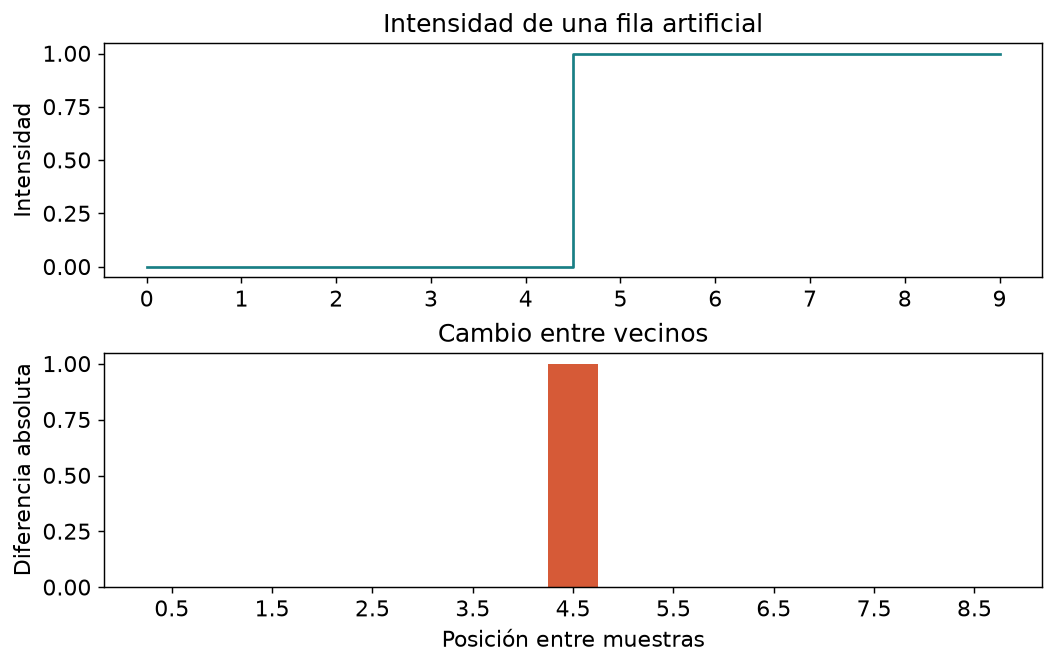

In [19]:
perfil = np.array([0,0,0,0,0,1,1,1,1,1], dtype=float)
diferencias = np.diff(perfil)
posiciones = np.arange(perfil.size)
centros_pares = np.arange(diferencias.size) + 0.5
fig, ax = plt.subplots(2, 1, figsize=(8, 5), layout="constrained")
ax[0].step(posiciones, perfil, where="mid", color="#197f85")
ax[0].set(title="Intensidad de una fila artificial", ylabel="Intensidad", xticks=posiciones)
ax[1].bar(centros_pares, np.abs(diferencias), width=0.5, color="#d65a37")
ax[1].set(title="Cambio entre vecinos", xlabel="Posición entre muestras", ylabel="Diferencia absoluta", xticks=centros_pares)
plt.show()

**Observa:** una zona brillante uniforme tiene intensidad alta pero cambio cercano a cero. **Cambia:** sustituye el escalón por `[0,0,0.1,0.3,0.6,0.9,1,1,1,1]` y repite; restaura después. **Pregunta:** ¿el cambio queda concentrado en un punto? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

en un escalón sí; en una transición suave se distribuye entre varios pares. Un detector de bordes no busca simplemente píxeles claros.

</details>



## 20 Medir cambios con Sobel en dos direcciones
En una imagen el cambio puede ocurrir horizontal o verticalmente. **Sobel** combina diferencias entre vecinos con un pequeño suavizado transversal. `axis=1` calcula el cambio horizontal en nuestra matriz mostrada; `axis=0`, el vertical. Juntaremos ambos con `sqrt(dx**2 + dy**2)`: la magnitud del gradiente.

El mapa resultante es **fuerza de cambio**, no una máscara y no una probabilidad de lesión. No normalizamos cada mapa a su propio máximo. Los valores son respuestas del operador discreto en esta escala, no una derivada calibrada por milímetro.

**El código línea por línea**

1. Mide cambio horizontal sobre la misma imagen ruidosa de antes.
2. Mide cambio vertical sobre esa imagen.
3. Combina ambos cambios en una magnitud no negativa.
4. Guarda un máximo común que reutilizaremos al comparar antes y después del suavizado.
5. Abre tres vistas de componentes y magnitud.
6. Muestra magnitudes para comparar sin confundir signos.
7. Conserva una escala numérica común en los tres paneles y guarda su representación.
8. Identifica el tipo de cambio y la orientación.
9. Muestra una única escala de color compartida por los tres mapas.
10. Muestra que el ruido también produce cambios fuertes entre vecinos.

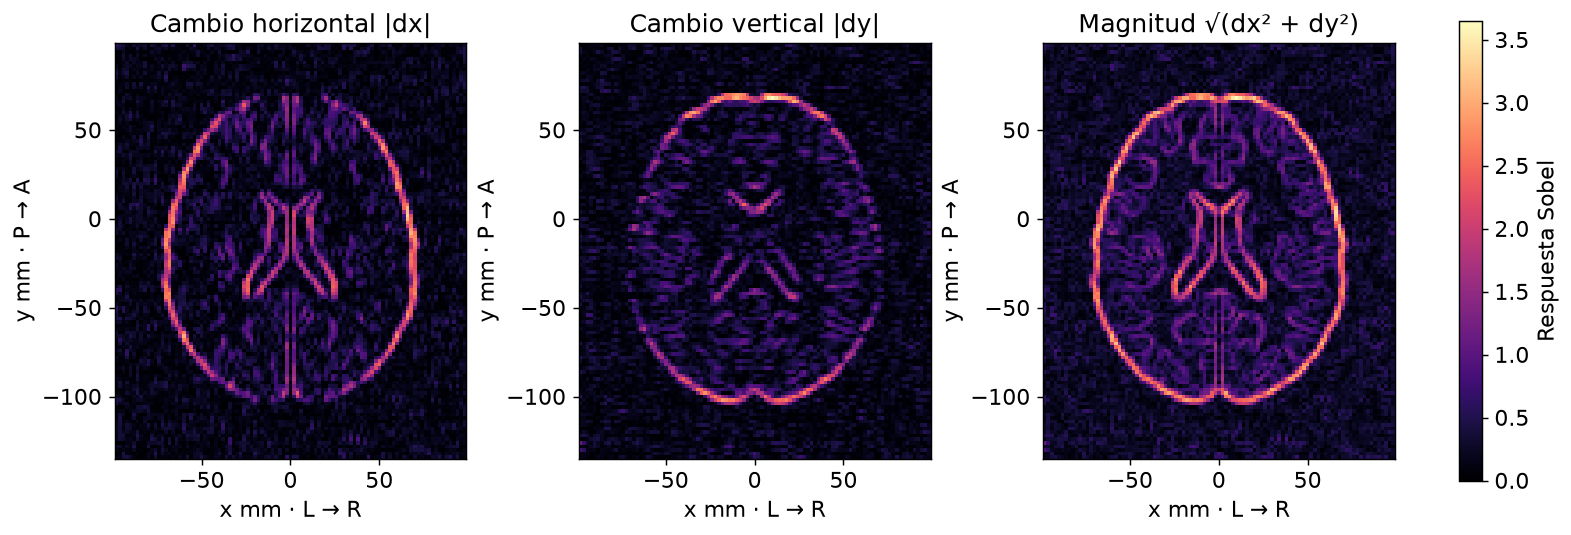

In [20]:
dx = ndimage.sobel(ruidosa, axis=1, mode="reflect")
dy = ndimage.sobel(ruidosa, axis=0, mode="reflect")
gradiente = np.sqrt(dx**2 + dy**2)
escala_bordes = float(gradiente.max())
fig, ax = plt.subplots(1, 3, figsize=(12, 4.5), layout="constrained")
for panel, matriz, titulo in zip(ax, [np.abs(dx), np.abs(dy), gradiente], ["Cambio horizontal |dx|", "Cambio vertical |dy|", "Magnitud √(dx² + dy²)"]):
    vista = panel.imshow(matriz, cmap="magma", origin="lower", extent=extension, vmin=0, vmax=escala_bordes)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
fig.colorbar(vista, ax=ax, shrink=0.8, label="Respuesta Sobel")
plt.show()

**Observa:** Sobel responde también al ruido; no sabe qué estructura es importante. **Cambia:** identifica visualmente una zona uniforme y otra de transición. **Pregunta:** ¿un punto brillante aquí significa intensidad MRI alta? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

significa un cambio local fuerte según este operador, aunque la imagen original fuera oscura en esa región.

</details>



## 21 Suavizar antes de detectar bordes
Ahora aplicaremos Sobel a la versión gaussiana de **la misma imagen ruidosa**, con sigma fijo de 1.2 píxeles. Compararemos magnitudes con **un único máximo común** y seleccionaremos bordes con **un único umbral numérico** de 0.6. No ajustaremos ni normalizaremos cada resultado por separado: eso podría ocultar que el filtro atenúa el gradiente. La selección binaria es una regla ilustrativa, no una frontera anatómica validada.

**El código línea por línea**

1. Fija explícitamente el suavizado a 1.2 píxeles para esta comparación.
2. Calcula cambio horizontal después de suavizar.
3. Calcula cambio vertical después de suavizar.
4. Forma la magnitud con la misma fórmula que antes.
5. Elige una escala compartida y evita un rango nulo en una imagen constante.
6. Usa el mismo umbral absoluto de respuesta Sobel antes y después.
7. Prepara dos magnitudes y dos selecciones con idéntica regla.
8. Describe qué se compara y actualiza los títulos al cambiar el umbral.
9. Separa arriba magnitudes y abajo selecciones binarias.
10. Recorre los cuatro paneles conservando su número.
11. Usa escala común para magnitudes y 0–1 para ambas máscaras.
12. Usa color para magnitud y blanco/negro para selección.
13. Muestra cada resultado sin normalización individual.
14. Mantiene nombres, orientación y unidades espaciales.
15. Usa el primer mapa para explicar la escala idéntica de las dos magnitudes superiores.
16. Presenta una comparación controlada antes y después.
17. Cuenta la selección sobre el corte completo en ambos casos.

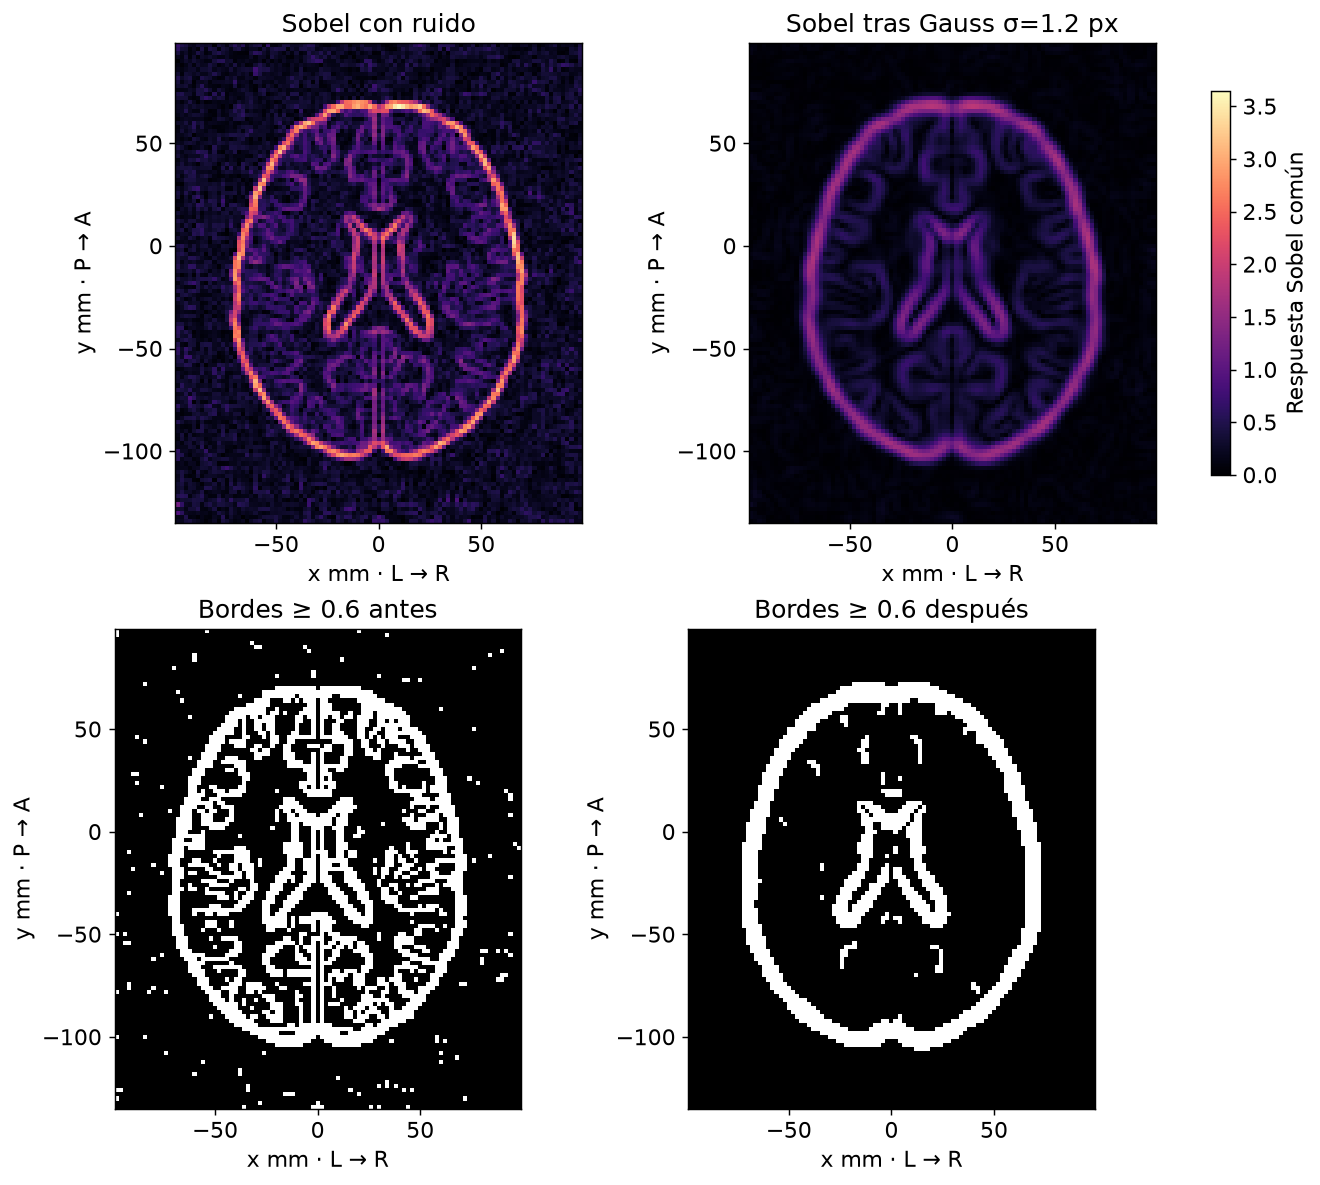

Umbral compartido: 0.6 | píxeles seleccionados antes/después: 2471 1495


In [21]:
suave_bordes = ndimage.gaussian_filter(ruidosa, sigma=1.2, mode="reflect")
dx_suave = ndimage.sobel(suave_bordes, axis=1, mode="reflect")
dy_suave = ndimage.sobel(suave_bordes, axis=0, mode="reflect")
gradiente_suave = np.sqrt(dx_suave**2 + dy_suave**2)
maximo_comun = max(float(gradiente.max()), float(gradiente_suave.max()), 1e-12)
umbral_borde = 0.6
mapas = [gradiente, gradiente_suave, gradiente >= umbral_borde, gradiente_suave >= umbral_borde]
titulos = ["Sobel con ruido", "Sobel tras Gauss σ=1.2 px", f"Bordes ≥ {umbral_borde} antes", f"Bordes ≥ {umbral_borde} después"]
fig, ax = plt.subplots(2, 2, figsize=(10, 9), layout="constrained")
for indice, panel in enumerate(ax.ravel()):
    tope_panel = maximo_comun if indice < 2 else 1
    color_panel = "magma" if indice < 2 else "gray"
    panel.imshow(mapas[indice], cmap=color_panel, origin="lower", extent=extension, vmin=0, vmax=tope_panel)
    panel.set(title=titulos[indice], xlabel="x mm · L → R", ylabel="y mm · P → A")
fig.colorbar(ax[0,0].images[0], ax=ax[0,:], shrink=0.8, label="Respuesta Sobel común")
plt.show()
print("Umbral compartido:", umbral_borde, "| píxeles seleccionados antes/después:", int((gradiente>=umbral_borde).sum()), int((gradiente_suave>=umbral_borde).sum()))

**Observa:** parte del cambio inducido por ruido disminuye; algunos detalles verdaderos también pueden debilitarse. **Cambia:** prueba umbral=0.4 y 0.8 en ambos mapas, luego vuelve a 0.6. **Pregunta:** ¿menos bordes significa mejor resultado? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no necesariamente. Hay que decidir qué estructura queremos conservar y evaluarlo con una referencia apropiada.

</details>



## 22 Reconstruir el recorrido completo
Hemos separado decisiones que suelen confundirse: **ver** una imagen, **describir** sus valores, **transformarlos** con un filtro y **crear una selección**. Una curva une igual intensidad; Sobel mide cambio espacial. El orden importa y debe documentarse.

La figura siguiente resume el recorrido. Su código solo coloca textos y flechas; no ejecuta un modelo ni procesa datos nuevos. Usar un algoritmo de procesamiento de imagen no significa que hayamos entrenado Machine Learning.

**El código línea por línea**

1. Resume cinco preguntas que guían un análisis reproducible.
2. Abre un espacio horizontal para el recorrido.
3. Define coordenadas de dibujo arbitrarias, no médicas.
4. Oculta ejes porque solo organizamos una explicación.
5. Recorre los cinco pasos con sus posiciones.
6. Coloca cada etapa en el centro de su espacio.
7. Evita dibujar una flecha después del último paso.
8. Une el paso actual con el siguiente.
9. Expresa el propósito del recorrido.
10. Presenta el mapa de conceptos terminado.

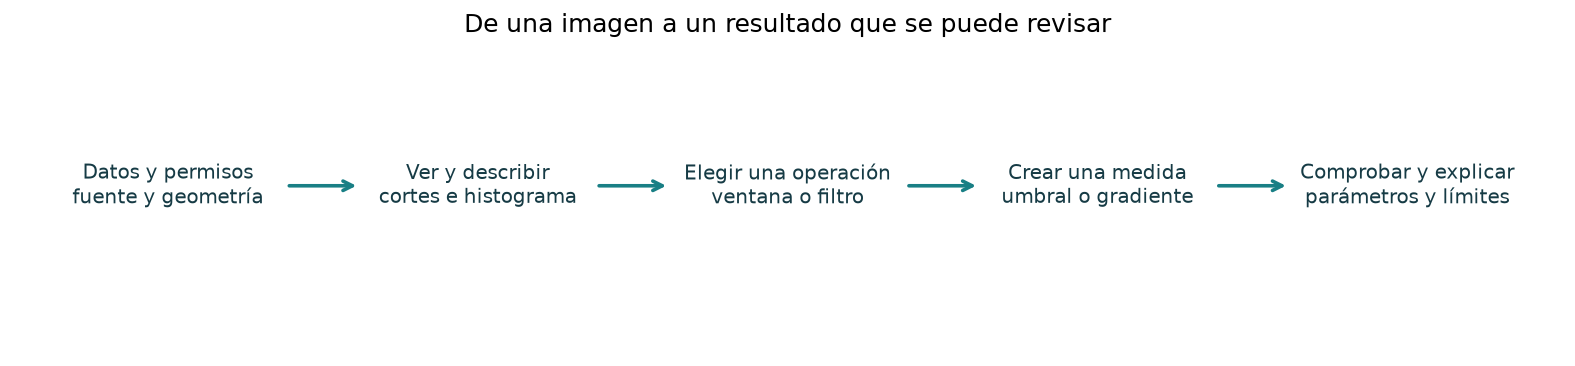

In [22]:
pasos_pipeline = ["Datos y permisos\nfuente y geometría", "Ver y describir\ncortes e histograma", "Elegir una operación\nventana o filtro", "Crear una medida\numbral o gradiente", "Comprobar y explicar\nparámetros y límites"]
fig, ax = plt.subplots(figsize=(12, 2.7), layout="constrained")
ax.set(xlim=(0,5), ylim=(0,1))
ax.axis("off")
for indice, texto in enumerate(pasos_pipeline):
    ax.text(indice+0.5, 0.55, texto, ha="center", va="center", fontsize=11, color="#163b45")
    if indice < 4:
        ax.annotate("", xy=(indice+1.12,0.55), xytext=(indice+0.88,0.55), arrowprops={"arrowstyle":"->", "color":"#197f85", "lw":2})
fig.suptitle("De una imagen a un resultado que se puede revisar", fontsize=14)
plt.show()

**Observa:** ninguna etapa convierte por sí sola un resultado en diagnóstico. **Cambia:** explica a tu compañero qué paso revisarías si una imagen parece girada o si un filtro borra detalles. **Pregunta:** ¿qué faltaría para Machine Learning supervisado? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

una pregunta, muchas personas independientes, etiquetas fiables, entrenamiento y evaluación en personas nuevas. Los cortes de una plantilla no son una cohorte.

</details>



### Cierre en tres preguntas
1. ¿Qué diferencia hay entre un píxel brillante y un gradiente grande? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

el primero es intensidad alta; el segundo es cambio local fuerte.

</details>


2. ¿Qué debería permanecer igual al comparar dos filtros? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

entrada, semilla, plano, escala de visualización y condiciones de evaluación; se declaran los parámetros de cada método.

</details>


3. ¿Qué demuestra una máscara por umbral? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

qué casillas cumplen una regla. No demuestra tejido, enfermedad ni generalización de un modelo.

</details>



### Anexo de privacidad antes de usar imágenes propias
Este cuaderno usa una **plantilla promedio pública**, con licencia y atribución en `FUENTES_Y_LICENCIAS.txt`. No incluye estudios propios. Si después incorporas imágenes de pacientes, prepara una copia local autorizada y desidentifícala **antes** de subirla a Colab, GitHub o cualquier servicio.

**DICOM** puede guardar nombres, identificadores, fechas, datos del centro, secuencias con referencias y etiquetas privadas. También puede contener texto en los píxeles. NIfTI y sus acompañantes pueden conservar metadatos o nombres identificables; imágenes de cabeza pueden mantener rasgos faciales. Cambiar el nombre del archivo o borrar `PatientName` no basta.

El proceso real requiere definir uso y destinatarios, aplicar un procedimiento institucional validado (con el perfil y opciones DICOM adecuados cuando corresponda), mantener coherentes las referencias, revisar metadatos y píxeles, evaluar riesgo de reidentificación y verificar antes de compartir. Si se conserva una clave que permite volver a identificar, es seudonimización. La autorización para uso no sustituye esta revisión. No damos aquí un script simplificado que prometa anonimización completa.

### Fuentes para continuar
- [Plantilla MNI152 en Nilearn 0.12.1](https://nilearn.github.io/0.12.1/modules/generated/nilearn.datasets.load_mni152_template.html) y [licencia y referencias McGill](https://www.bic.mni.mcgill.ca/ServicesAtlases/ICBM152NLin2009).
- [NiBabel y coordenadas](https://nipy.org/nibabel/coordinate_systems.html).
- [Histogramas Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) y [curvas de nivel](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.contour.html).
- [Filtro gaussiano SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.gaussian_filter.html), [media local](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.uniform_filter.html), [mediana](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.median_filter.html) y [Sobel](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.sobel.html).
- [DICOM PS3.15 anexo E](https://dicom.nema.org/medical/dicom/current/output/chtml/part15/chapter_E.html).

Referencias del atlas: Fonov y colaboradores, *NeuroImage* 54(1), 2011, [doi:10.1016/j.neuroimage.2010.07.033](https://doi.org/10.1016/j.neuroimage.2010.07.033); Fonov y colaboradores, *NeuroImage* 47 suplemento 1, 2009, [doi:10.1016/S1053-8119(09)70884-5](https://doi.org/10.1016/S1053-8119(09)70884-5). Consulta de las referencias de procesamiento: 16 de noviembre de 2026.

## 23 Ampliación para calcular media y mediana a mano
Esta actividad opcional usa nueve valores artificiales: ocho valen 10 y uno vale 90. La media suma todos y divide por nueve; la mediana ordena y toma el quinto. El ejemplo explica el comportamiento frente a un valor extremo, no compara desempeño clínico.

**El código línea por línea**

1. Define una vecindad artificial de tres filas por tres columnas.
2. Suma sus nueve valores y divide por nueve.
3. Ordena los nueve valores y toma el central.
4. Crea un panel numérico y otro para los resultados.
5. Dibuja cada casilla de esta escala artificial de 0 a 100.
6. Recorre las tres filas de la vecindad.
7. Recorre las tres columnas de cada fila.
8. Escribe los valores para que se puedan contar a mano.
9. Identifica la vecindad usada.
10. Oculta ejes en el panel explicativo.
11. Muestra ambos cálculos con números grandes.
12. Relaciona el valor extremo con dos respuestas distintas.

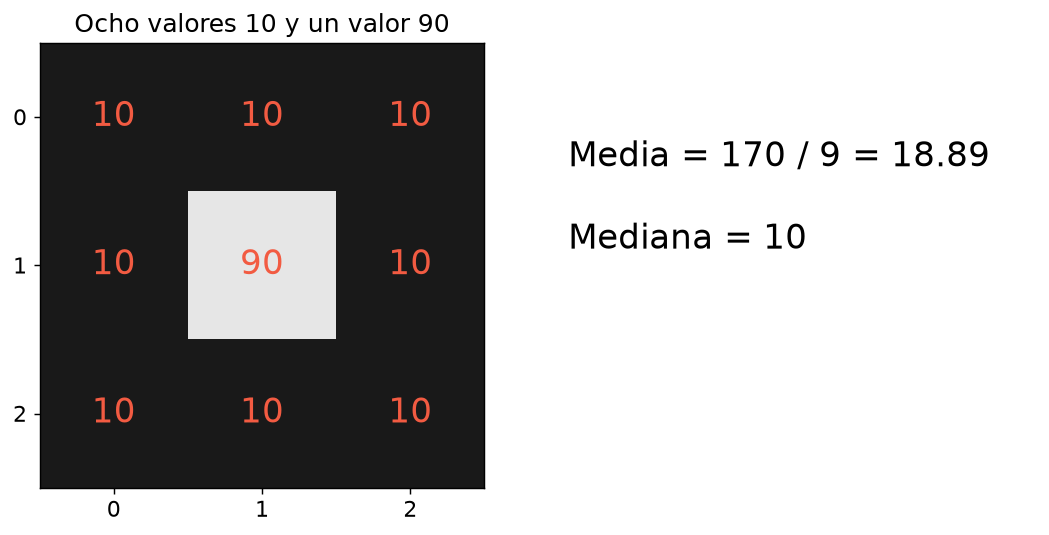

In [23]:
vecindad = np.array([[10,10,10],[10,90,10],[10,10,10]], dtype=float)
promedio_manual = vecindad.mean()
mediana_manual = np.median(vecindad)
fig, ax = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
ax[0].imshow(vecindad, cmap="gray", vmin=0, vmax=100, interpolation="nearest")
for fila in range(3):
    for columna in range(3):
        ax[0].text(columna, fila, int(vecindad[fila,columna]), ha="center", va="center", color="#f25b42", fontsize=19)
ax[0].set(title="Ocho valores 10 y un valor 90", xticks=range(3), yticks=range(3))
ax[1].axis("off")
ax[1].text(0.08, 0.65, f"Media = 170 / 9 = {promedio_manual:.2f}\n\nMediana = {mediana_manual:.0f}", fontsize=19, va="center")
plt.show()

**Observa:** 90 eleva el promedio, pero no cambia la mediana en este caso. **Cambia:** prueba 900 en el centro; el gráfico saturará, pero los números y cálculos seguirán mostrando su valor. Después restaura 90. **Pregunta:** ¿la mediana siempre preserva el detalle? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no; depende de la vecindad y de la estructura. El ejemplo solo describe este caso.

</details>



## 24 Ampliación para observar ruido de impulsos
Construiremos una perturbación distinta del ruido normal: sustituiremos el **2% de las posiciones del corte** por ceros o unos. Elegimos posiciones únicas con una semilla fija. Partimos de una copia **del corte limpio**, no de la matriz con ruido normal. Los tres filtros recibirán exactamente la misma nueva entrada. La demostración describe un artificio de píxeles extremos, no el proceso completo de adquisición MRI.

**El código línea por línea**

1. Crea un generador propio, independiente del usado para el ruido normal.
2. Calcula cuántas posiciones únicas sustituiremos, redondeando al entero más cercano.
3. Escoge posiciones sin repetirlas.
4. Preserva el corte de referencia y crea la nueva entrada artificial.
5. Divide el conjunto de posiciones en dos grupos de tamaño similar.
6. Coloca ceros en el primer grupo de posiciones.
7. Coloca unos en el segundo grupo.
8. Aplica los tres filtros a la misma entrada, con el modo reflect por defecto.
9. Declara la perturbación y los parámetros.
10. Coloca entrada y resultados en cuatro paneles legibles.
11. Recorre cada comparación sin cambiar la entrada.
12. Mantiene la misma ventana de intensidad en todos.
13. Conserva orientación y coordenadas.
14. Muestra cómo responden los filtros a posiciones extremas aisladas.
15. Distingue posiciones asignadas de valores efectivamente distintos.

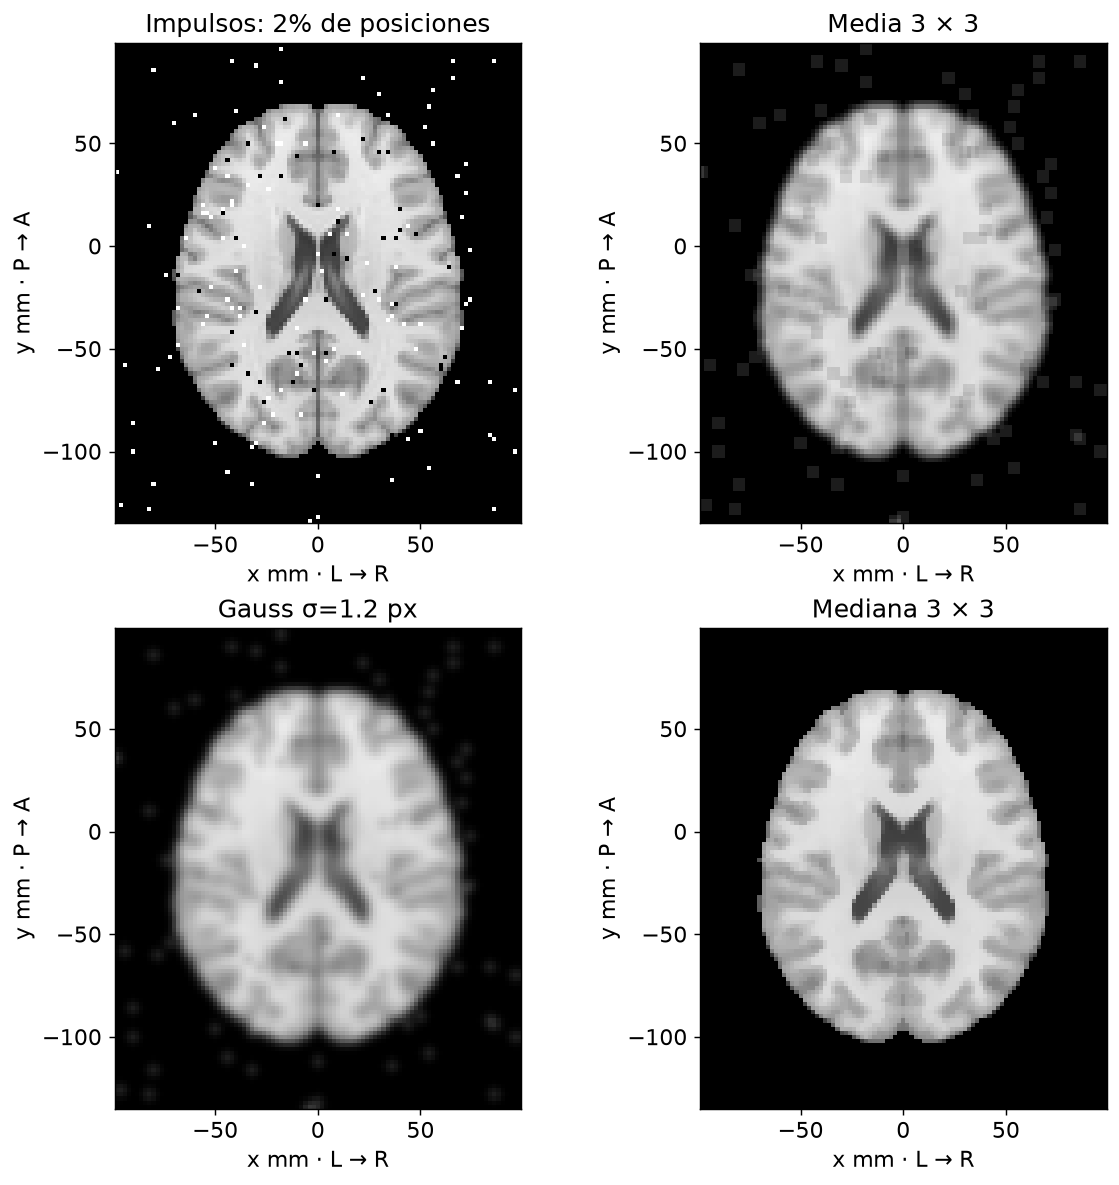

Posiciones sustituidas: 232 de 11583 | no necesariamente todas cambian de valor


In [24]:
rng_impulsos = np.random.default_rng(2026)
numero_impulsos = round(0.02 * corte.size)
posiciones_impulsos = rng_impulsos.choice(corte.size, size=numero_impulsos, replace=False)
impulsos = corte.copy()
mitad = numero_impulsos // 2
impulsos.flat[posiciones_impulsos[:mitad]] = 0
impulsos.flat[posiciones_impulsos[mitad:]] = 1
resultados = [impulsos, ndimage.uniform_filter(impulsos, 3), ndimage.gaussian_filter(impulsos, 1.2), ndimage.median_filter(impulsos, 3)]
titulos = ["Impulsos: 2% de posiciones", "Media 3 × 3", "Gauss σ=1.2 px", "Mediana 3 × 3"]
fig, ax = plt.subplots(2, 2, figsize=(9, 9), layout="constrained")
for panel, matriz, titulo in zip(ax.ravel(), resultados, titulos):
    panel.imshow(matriz, cmap="gray", origin="lower", extent=extension, vmin=0, vmax=1)
    panel.set(title=titulo, xlabel="x mm · L → R", ylabel="y mm · P → A")
plt.show()
print("Posiciones sustituidas:", numero_impulsos, "de", corte.size, "| no necesariamente todas cambian de valor")

**Observa:** el patrón de perturbación es diferente del ruido normal. La mediana puede retirar puntos extremos aislados, pero también puede alterar detalle. **Cambia:** compara esta figura con la lección 18; no compares con una escala distinta. **Pregunta:** ¿este ejemplo prueba que la mediana es la mejor opción para una MRI real? 

<details>
<summary>Ver la respuesta después de intentarlo</summary>

no. El tipo de ruido, la tarea y una evaluación adecuada determinan la elección.

</details>

